# Multimodal Precision Agriculture via Spatio Temporal Cross Modal Attention

**Course:** COMP 6001 Capstone  
**Student:** Natarajan Sellaiya (A1815352)  
**Proposed model:** Spatio-Temporal Cross-Modal Gated Network (ST-CGN)

This notebook is a complete, from-scratch PyTorch study of crop-anomaly classification from two aligned modalities:

- a multispectral image, shape `(4, H, W)`, with red, green, blue, and near-infrared channels
- a daily meteorological token sequence, shape `(T,)`, drawn from a small climate vocabulary

The label is one of five agronomic states: Healthy, Nitrogen Deficiency, Drought Stress, Weed Infestation, and Waterway Encroachment.

ST-CGN keeps a spatial feature map and a temporal hidden-state sequence, then couples them with a climate-addressed spatial attention mask and a climate-conditioned channel gate. Four baselines are trained under the same splits, optimizer, loss, and epoch budget: a unimodal CNN, a unimodal BiLSTM, early fusion, and late fusion. Comparison uses macro precision, macro recall, accuracy, and macro F1 on stratified 5-fold cross-validation, followed by a paired two-tailed t-test and a Wilcoxon signed-rank test.

## How to run this notebook on Colab Pro+

1. Open the notebook in Google Colab and set the runtime to **GPU (A100)**.
2. Leave `DEBUG_MODE = False` in the configuration cell for the graded run. Set it to `True` only for a short CPU smoke test.
3. Optional real data: mount Drive yourself, then place these files in `/content/drive/MyDrive/COMP6001_STCGN/` (or in a local `data/` directory):
   - `images.npy`, float array `(N, 4, H, W)` in channel-first order, or `(N, H, W, 4)`. Values in `[0, 1]` or `[0, 255]`.
   - `tokens.npy`, int array `(N, T)`. Token `0` is reserved for padding. Other ids must lie in `[1, 11]`.
   - `labels.npy`, int array `(N,)` with values in `{0, 1, 2, 3, 4}`.
   - `climate.csv`, optional. Columns: `precip`, `temp`, `precip_deficit`, `thermal_spike`, `humidity`, `soil_moisture`.
4. Use **Runtime → Run all**. Do not skip cells. Later cells depend on objects created above them.
5. Figures, fold metrics, out-of-fold predictions, and `summary.json` are written to `outputs/`, or to `MyDrive/COMP6001_STCGN_outputs/` when Drive is already mounted.

Drive is not mounted automatically. An OAuth prompt would block **Run all**. If the directory above is absent, the notebook builds a controlled synthetic benchmark and says so in the log. That benchmark is a stress test of cross-modal spatial selection, not a substitute for a field survey. Section 7 states the resulting limit on interpretation.

**Expected runtime.** Debug mode is a few minutes on CPU. The full setting (2,000 images at 128×128, 15 epochs, 5 models, 5 folds) is sized for an A100 and typically finishes well inside an hour.

**Primary endpoint, declared before fitting.** Macro F1 on the validation fold, computed at the final epoch. Accuracy is reported because the rubric asks for it, but it is not the decision metric: the class prior is intentionally imbalanced. Statistical tests use the five fold-level macro-F1 numbers. The image is not the experimental unit.

## Requirements

Pinned for Colab. The setup cell installs a package only when its import fails, and it does not reinstall PyTorch when a CUDA build is already present.

```
torch>=2.1
numpy>=1.24
pandas>=2.0
matplotlib>=3.7
seaborn>=0.13
scikit-learn>=1.3
scipy>=1.11
```

`torchvision`, `torchaudio`, and `thop` are optional. This study does not call a pretrained vision or audio model. FLOPs are measured by a local profiler so a missing `thop` install cannot change the result.

In [1]:
"""Install missing scientific packages without disturbing an existing CUDA torch build."""
import importlib
import subprocess
import sys


def _pip_install(package: str) -> None:
    print(f"Installing {package} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])


def ensure(package: str, module: str, required: bool) -> None:
    try:
        importlib.import_module(module)
        print(f"ready: {module}")
    except ImportError:
        try:
            _pip_install(package)
            importlib.invalidate_caches()
            importlib.import_module(module)
            print(f"installed: {module}")
        except Exception as exc:
            message = f"could not import {module} ({exc})"
            if required:
                raise RuntimeError(message) from exc
            print("optional skip:", message)


try:
    import torch
    print(f"ready: torch {torch.__version__} | cuda={torch.cuda.is_available()}")
except ImportError:
    _pip_install("torch")
    ensure("torchvision", "torchvision", required=False)
    ensure("torchaudio", "torchaudio", required=False)

for _package, _module, _required in (
    ("numpy", "numpy", True),
    ("pandas", "pandas", True),
    ("matplotlib", "matplotlib", True),
    ("seaborn", "seaborn", True),
    ("scikit-learn", "sklearn", True),
    ("scipy", "scipy", True),
):
    ensure(_package, _module, _required)

ensure("torchvision", "torchvision", required=False)
ensure("thop", "thop", required=False)

ready: torch 2.11.0+cu130 | cuda=True
ready: numpy
ready: pandas
ready: matplotlib
ready: seaborn
ready: sklearn
ready: scipy
ready: torchvision
Installing thop ...
installed: thop


## 0. Environment, device, and configuration

Seeds are fixed at 42. CuDNN convolution autotune is disabled so fold comparisons are not confounded by algorithm selection. TensorFloat-32 is left at the PyTorch default on Ampere GPUs: turning it off would change speed on an A100 more than it would change this small model, and the limitation is recorded in Section 3.

`DEBUG_MODE = False` is the graded configuration. `True` shrinks the image, the sample size, the width, and the epoch budget so the same code path can be checked quickly.

The configuration cell writes two files into `OUTPUT_DIR` before any training starts: `requirements.txt`, pinned to the packages imported in this runtime, and `README.md`, with the Colab reproduction steps, the \(O(H \cdot W \cdot T)\) attention cost, the \(32^2 \times 30 \rightarrow 4^2 \times 30\) pooling reduction on the graded tile, and the edge-case handling for softmax, GPU memory, missing weather logs, and class imbalance.

In [2]:
"""Device, seeds, output directory, and the single experiment configuration."""
import gc
import os
import math
import random
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)


def configure_matplotlib() -> None:
    try:
        get_ipython().run_line_magic("matplotlib", "inline")
    except Exception:
        pass
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update(
        {
            "figure.dpi": 120,
            "savefig.dpi": 200,
            "axes.titlesize": 12,
            "axes.labelsize": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "legend.frameon": False,
        }
    )


def set_seed(seed: int) -> None:
    """Fix Python, NumPy, and PyTorch RNGs for a reproducible fold."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def release_memory() -> None:
    """Return cached CUDA blocks after a model is discarded."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


@dataclass
class Config:
    """All experiment knobs. Call ``apply_profile`` after construction.

    The profile is selected only by ``DEBUG_MODE``. Edit the numbers inside
    ``apply_profile`` rather than assigning contradictory sizes afterwards.
    """

    DEBUG_MODE: bool = False
    SEED: int = 42
    data_dir: str = "/content/drive/MyDrive/COMP6001_STCGN"
    n_folds: int = 5
    in_channels: int = 4
    num_classes: int = 5
    vocab_size: int = 12
    pad_idx: int = 0
    attn_grid: int = 4
    dropout: float = 0.10
    lr: float = 1e-3
    weight_decay: float = 1e-4
    grad_clip: float = 1.0
    num_samples: int = 2000
    image_size: int = 128
    seq_len: int = 30
    epochs: int = 12
    batch_size: int = 32
    cnn_channels: tuple = (32, 64, 128)
    embed_dim: int = 48
    lstm_hidden: int = 64
    lstm_layers: int = 2
    attn_dim: int = 64
    head_dim: int = 128

    def apply_profile(self) -> "Config":
        if self.DEBUG_MODE:
            self.num_samples = 1000
            self.image_size = 64
            self.seq_len = 24
            self.epochs = 8
            self.batch_size = 32
            self.cnn_channels = (16, 32, 48)
            self.embed_dim = 32
            self.lstm_hidden = 32
            self.lstm_layers = 2
            self.attn_dim = 32
            self.head_dim = 64
        else:
            self.num_samples = 2000
            self.image_size = 128
            self.seq_len = 30
            self.epochs = 15
            self.batch_size = 32
            self.cnn_channels = (32, 64, 128)
            self.embed_dim = 48
            self.lstm_hidden = 64
            self.lstm_layers = 2
            self.attn_dim = 64
            self.head_dim = 128
        if self.image_size % 4 != 0 or self.image_size < 32:
            raise ValueError("image_size must be a multiple of 4 and at least 32.")
        if self.attn_grid < 2 or self.attn_grid % 2 != 0:
            raise ValueError("attn_grid must be a positive even integer so quadrants align.")
        return self


CLASS_NAMES = (
    "Healthy",
    "Nitrogen Deficiency",
    "Drought Stress",
    "Weed Infestation",
    "Waterway Encroachment",
)
CLIMATE_COLUMNS = (
    "Precipitation",
    "Temperature",
    "Precipitation deficit",
    "Thermal spike",
    "Humidity",
    "Soil moisture",
)
MODEL_ORDER = (
    "ST-CGN",
    "Unimodal CNN",
    "Unimodal BiLSTM",
    "Early Fusion",
    "Late Fusion",
)
MODEL_COLORS = {
    "ST-CGN": "#0072B2",
    "Unimodal CNN": "#E69F00",
    "Unimodal BiLSTM": "#009E73",
    "Early Fusion": "#CC79A7",
    "Late Fusion": "#D55E00",
}

configure_matplotlib()
set_seed(42)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"device: cuda | {gpu_name} | {gpu_gb:.1f} GiB")
else:
    DEVICE = torch.device("cpu")
    print("device: cpu")
print(f"torch {torch.__version__}")

# Graded run. Set DEBUG_MODE = True for a short CPU smoke test.
DEBUG_MODE = False
if os.environ.get("STCGN_DEBUG", "0") == "1":
    DEBUG_MODE = True
CFG = Config(DEBUG_MODE=DEBUG_MODE).apply_profile()
print(f"DEBUG_MODE={CFG.DEBUG_MODE}")

OUTPUT_DIR = Path("outputs")
_drive_out = Path("/content/drive/MyDrive/COMP6001_STCGN_outputs")
if _drive_out.parent.exists():
    OUTPUT_DIR = _drive_out
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"output directory: {OUTPUT_DIR.resolve()}")
display(pd.DataFrame([asdict(CFG)]).T.rename(columns={0: "value"}))


def _installed_version(distribution: str) -> str | None:
    """Return the installed distribution version, or None when it is absent."""
    try:
        from importlib.metadata import version
        return version(distribution)
    except Exception:
        return None


def write_requirements(output_dir: Path) -> Path:
    """Pin the study dependencies from the interpreter that is actually running."""
    names = (
        "torch",
        "torchvision",
        "scikit-learn",
        "scipy",
        "matplotlib",
        "seaborn",
        "pandas",
        "numpy",
        "thop",
    )
    lines = [
        "# COMP 6001 capstone",
        "# Natarajan Sellaiya (A1815352)",
        "# Multimodal Precision Agriculture via Spatio Temporal Cross Modal Attention",
        "# Versions are pinned from the interpreter that executed this notebook.",
    ]
    missing = []
    for name in names:
        found = _installed_version(name)
        if found is None:
            missing.append(name)
            lines.append(f"# {name} is not installed in this interpreter")
        else:
            lines.append(f"{name}=={found}")
    path = output_dir / "requirements.txt"
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    print(f"saved {path}")
    if missing:
        print("not installed in this interpreter, so not version-pinned:", ", ".join(missing))
    return path


def write_readme(output_dir: Path, cfg: Config) -> Path:
    """Write the reproduction guide, complexity argument, and edge-case notes."""
    native = cfg.image_size // 4
    live_native_scores = native * native * cfg.seq_len
    live_pooled_scores = cfg.attn_grid * cfg.attn_grid * cfg.seq_len
    graded_native = 32 * 32 * 30
    graded_pooled = 4 * 4 * 30
    text = f"""# Multimodal Precision Agriculture via Spatio Temporal Cross Modal Attention

**Course:** COMP 6001 Capstone
**Student:** Natarajan Sellaiya (A1815352)
**Model:** Spatio-Temporal Cross-Modal Gated Network (ST-CGN)

## Overview

ST-CGN classifies a crop canopy into five states (Healthy, Nitrogen Deficiency, Drought Stress, Weed Infestation, Waterway Encroachment) from two aligned inputs:

- a multispectral tile, shape `(4, H, W)`, channels red, green, blue, and near-infrared
- a meteorological token sequence, shape `(T,)`, with token `0` reserved for padding

The network is written from `nn.Conv2d`, `nn.Linear`, and `nn.LSTM`. It is compared with four baselines trained on the same stratified folds and the same optimizer: a unimodal CNN, a unimodal BiLSTM, early fusion, and late fusion. The primary endpoint is final-epoch macro F1.

This file is written by the notebook into the output directory at the start of a run. The numbers below follow the configuration that produced the file. `DEBUG_MODE` for this run is `{cfg.DEBUG_MODE}`.

## System requirements

- Google Colab Pro+ with an NVIDIA A100 is the graded runtime. A CPU run is only for `DEBUG_MODE = True`.
- Python 3.10 or newer.
- Packages pinned in `requirements.txt` in this same directory: `torch`, `torchvision`, `scikit-learn`, `scipy`, `matplotlib`, `seaborn`, `pandas`, `numpy`, and `thop`.
- `torchvision` and `thop` are not used as pretrained model factories. `thop` is an optional cross-check. The authoritative FLOP count is the notebook's own forward-hook profiler.
- Disk space for `outputs/`: figures, CSV tables, `oof_predictions.npz`, and `summary.json`.
- Do not upgrade an existing CUDA build of PyTorch. The setup cell installs a package only when its import fails, and it does not reinstall torch when torch already imports.

## Reproduce the graded run in Google Colab Pro+

1. Upload `ST_CGN_Precision_Agriculture.ipynb` to Google Drive or open it directly in Colab.
2. Menu path: **Runtime → Change runtime type → GPU → A100**.
3. In the configuration cell, leave `DEBUG_MODE = False`. That profile uses 2,000 images, 128×128 tiles, sequence length 30, and 15 epochs. Set `DEBUG_MODE = True` only for a short smoke test.
4. Optional real data, already mounted, in `/content/drive/MyDrive/COMP6001_STCGN/`:
   - `images.npy`, float array `(N, 4, H, W)` or `(N, H, W, 4)`, values in `[0, 1]` or `[0, 255]`
   - `tokens.npy`, int array `(N, T)`, ids in `[0, 11]`, with `0` meaning pad
   - `labels.npy`, int array `(N,)`, values in `{{0, 1, 2, 3, 4}}`
   - `climate.csv`, optional, columns `precip`, `temp`, `precip_deficit`, `thermal_spike`, `humidity`, `soil_moisture`
5. Do not call `drive.mount` inside **Run all**. An OAuth prompt blocks the run. Mount Drive yourself first if the files live there.
6. Menu path: **Runtime → Run all**. Cells are ordered. Skipping the training cell leaves the statistical tests without fold scores.
7. Collect artifacts from `outputs/`, or from `/content/drive/MyDrive/COMP6001_STCGN_outputs/` when Drive is already mounted.

If the three `.npy` files are absent, the notebook builds a controlled synthetic benchmark and prints that fact. The label in that benchmark is the spectral pattern inside the quadrant named by the order of the weather tokens. It is a mechanism test. It is not a field survey.

## Computational complexity

Let `n` be the image side, `t` the number of daily tokens, `d` the attention width, and `R` the pooled grid. A cross-modal score between every spatial site and every day is `O(H · W · T)` before any constant factors from the channel width. On a raw 128×128 tile and a 30-day log that product is `128² × 30` scores per sample, which is the memory term that exhausts a GPU.

The residual backbone uses stride 4, so the native map of a 128×128 tile is 32×32. Attention on that map, still before pooling, forms

`32² × 30 = {graded_native:,}` scores per sample.

Adaptive average pooling to a 4×4 grid is applied before `Q K^T` is formed. The mask then costs

`4² × 30 = {graded_pooled:,}` scores per sample.

That is a 64-fold reduction of the spatial-temporal product (`{graded_native:,}` to `{graded_pooled:,}`), and each image quadrant remains a 2×2 block on the grid. The Big-O term falls from `O(H' W' T d)` with `H' = W' = 32` to `O(R² T d)` with `R = 4`. Memory for the mask falls the same way: `O(B · 32 · 32 · T)` becomes `O(B · 4 · 4 · T)`.

This run's live settings are image side `{cfg.image_size}`, sequence length `{cfg.seq_len}`, attention grid `{cfg.attn_grid}`. The native map is `{native}×{native}` (`{live_native_scores:,}` scores) and the pooled mask is `{cfg.attn_grid}×{cfg.attn_grid}` (`{live_pooled_scores:,}` scores). Parameter counts and measured FLOPs are written to `complexity.csv` and `07_complexity.png` by Section 3. The receptive field of the residual stack is 23 input pixels, which is local on a 128-pixel tile and is why a deeper 3×3 tower is not used.

Early fusion is `O(n² + t)` because it keeps only channel moments and a mean embedding. Late fusion pays for the CNN and the BiLSTM and does not build the `R² t` mask. ST-CGN pays for both encoders and for that small mask. The mask is the only term that can select a site.

## Edge cases and limitations

- **Softmax stability.** Scores are divided by `sqrt(d)` and clamped to `[-50, 50]`. Padded days are filled with `-50` before the spatial softmax. An all-pad row makes a temporal softmax undefined; those outputs are replaced with zeros and the visual readout is set to 0, so a missing log cannot inject NaN.
- **CUDA out of memory.** The dangerous activation is the attention map `B × R² × T` together with the convolutional maps, not the parameter count. The training loop clears the cache and raises an error that names `batch_size` and `image_size` as the knobs to lower. `DEBUG_MODE = True` is the safe fallback.
- **Missing weather logs.** Token `0` is padding. A row of pads is kept, not dropped. The temporal gate and the masked mean ignore those steps. Internal pads are left-aligned, which keeps a usable sequence and shifts absolute time; a field logger should emit an explicit missing-day token instead of a gap.
- **Class imbalance.** Healthy is the majority class by construction in the synthetic prior. The loss uses inverse-frequency weights fit on the training fold only and rescaled to mean 1. The reported endpoint is macro F1, so the minority classes keep an equal vote. Accuracy is reported and is not the decision metric.
- **BatchNorm.** The training loader drops a trailing batch only when the fold contains at least two full batches, so a batch of one does not update BatchNorm. Evaluation still scores every validation sample.
- **What the synthetic ceiling does not mean.** A high ST-CGN score on the fallback generator shows that the mask can recover a quadrant-scale interaction that pooling cannot represent. It does not estimate accuracy on a particular farm, season, or sensor.

## Artifacts

| File | Contents |
| --- | --- |
| `01_class_distribution.png` … `06_interaction_map.png` | Exploratory figures |
| `07_complexity.png`, `complexity.csv` | Parameters, FLOPs, Big-O |
| `08_convergence.png` … `16_paired_folds.png` | Training curves, metrics, ROC/PR, attention, gates, paired folds |
| `fold_metrics.csv`, `summary_metrics.csv`, `per_class_f1.csv` | Fold and aggregate scores |
| `linear_probes.csv` | Orderless ceilings and the privileged oracle |
| `statistical_tests.csv` | Paired t-test and Wilcoxon results |
| `oof_predictions.npz`, `summary.json`, `environment.txt` | Predictions and the run record |
| `requirements.txt`, `README.md` | This directory's pins and this guide |
"""
    path = output_dir / "README.md"
    path.write_text(text, encoding="utf-8")
    print(f"saved {path}")
    return path


write_requirements(OUTPUT_DIR)
write_readme(OUTPUT_DIR, CFG)


device: cuda | NVIDIA A100-SXM4-80GB | 79.3 GiB
torch 2.11.0+cu130
DEBUG_MODE=False
output directory: /content/outputs


,value
DEBUG_MODE,False
SEED,42
data_dir,/content/drive/MyDrive/COMP6001_STCGN
n_folds,5
in_channels,4
num_classes,5
vocab_size,12
pad_idx,0
attn_grid,4
dropout,0.1


saved outputs/requirements.txt
saved outputs/README.md


PosixPath('outputs/README.md')

## 1. Multimodal data and exploratory analysis

### Data contract

Each sample is a triple `(image, token sequence, label)`. Climate scalars, when present, are metadata for the correlation analysis. They are not model inputs. The networks see only the image tensor and the token ids. Giving the classifier the pre-aggregated climate vector would short-circuit the temporal encoder and is intentionally not done.

Token `0` is padding. A row of padding is a missing meteorological log, not a dropped sample. Internal padding is left-aligned and a warning is printed, because a gap in the middle would otherwise shift the absolute time index that the location code depends on.

### Controlled synthetic process

If the Drive files are absent, samples are drawn from a fully specified interaction so the fusion comparison has a known right answer.

1. Draw an imbalanced label, with Healthy as the majority class.
2. Draw a spectral pattern and a climate regime that together produce that label. The same pattern maps to different labels under different regimes. Drought and waterway encroachment, in particular, can share a low near-infrared patch; the regime decides which process it is.
3. Paint the true pattern into a random quadrant and a conflicting pattern into the opposite quadrant. The other two quadrants stay a healthy canopy. Global color averages therefore mix the true pattern with a distractor.
4. Encode the regime as a bag of weather tokens, and encode the trusted quadrant only as the **position** of a marker burst inside that bag. Every quadrant uses the same multiset of tokens. An average embedding cannot see the burst position. A BiLSTM can.

The privileged oracle that is allowed to average pixels inside the true quadrant, and is also given the climate metadata, is linearly separable. An orderless pooling of the whole image is not. That gap is the research target. It is also why a high ST-CGN score on this fallback data supports the mechanism without licensing a claim about a particular farm.

In [3]:
"""Vocabulary, synthetic interaction process, real-data loader, and dataset."""
PAD = 0
PRECIP_LOW, PRECIP_MED, PRECIP_HIGH = 1, 2, 3
TEMP_LOW, TEMP_MED, TEMP_HIGH = 4, 5, 6
HUM_LOW, HUM_HIGH = 7, 8
SOIL_LOW, SOIL_HIGH = 9, 10
MARKER = 11

TOKEN_NAMES = {
    0: "PAD",
    1: "PRECIP_LOW",
    2: "PRECIP_MED",
    3: "PRECIP_HIGH",
    4: "TEMP_LOW",
    5: "TEMP_MED",
    6: "TEMP_HIGH",
    7: "HUM_LOW",
    8: "HUM_HIGH",
    9: "SOIL_LOW",
    10: "SOIL_HIGH",
    11: "MARKER",
}
PATTERNS = ("uniform", "chlorosis", "low_nir", "texture", "water_band")
REGIMES = ("mild", "hot_dry", "hot_wet", "cool_wet")
LABEL_OF = {
    ("uniform", "mild"): 0,
    ("uniform", "hot_dry"): 0,
    ("uniform", "hot_wet"): 0,
    ("uniform", "cool_wet"): 0,
    ("chlorosis", "mild"): 1,
    ("chlorosis", "hot_dry"): 1,
    ("chlorosis", "hot_wet"): 1,
    ("chlorosis", "cool_wet"): 0,
    ("low_nir", "mild"): 0,
    ("low_nir", "hot_dry"): 2,
    ("low_nir", "hot_wet"): 0,
    ("low_nir", "cool_wet"): 4,
    ("texture", "mild"): 0,
    ("texture", "hot_dry"): 2,
    ("texture", "hot_wet"): 3,
    ("texture", "cool_wet"): 3,
    ("water_band", "mild"): 0,
    ("water_band", "hot_dry"): 0,
    ("water_band", "hot_wet"): 4,
    ("water_band", "cool_wet"): 4,
}
REGIME_PROPS = {
    "mild": {TEMP_MED: 0.40, PRECIP_MED: 0.40, HUM_LOW: 0.10, SOIL_HIGH: 0.10},
    "hot_dry": {TEMP_HIGH: 0.35, PRECIP_LOW: 0.35, SOIL_LOW: 0.20, HUM_LOW: 0.10},
    "hot_wet": {TEMP_HIGH: 0.30, PRECIP_HIGH: 0.30, HUM_HIGH: 0.25, SOIL_HIGH: 0.15},
    "cool_wet": {TEMP_LOW: 0.30, PRECIP_HIGH: 0.30, SOIL_HIGH: 0.25, HUM_HIGH: 0.15},
}
REGIME_CLIMATE = {
    "mild": np.array([0.52, 0.46, 0.18, 0.12, 0.48, 0.57], dtype=np.float32),
    "hot_dry": np.array([0.10, 0.86, 0.90, 0.84, 0.18, 0.14], dtype=np.float32),
    "hot_wet": np.array([0.84, 0.78, 0.16, 0.48, 0.88, 0.76], dtype=np.float32),
    "cool_wet": np.array([0.88, 0.24, 0.10, 0.08, 0.90, 0.93], dtype=np.float32),
}
CLASS_PRIOR = np.array([0.42, 0.22, 0.16, 0.12, 0.08], dtype=np.float64)


def quadrant_slices(quadrant: int, size: int) -> tuple[slice, slice]:
    """Return row and column slices for TL, TR, BL, BR."""
    mid = size // 2
    rows = slice(0, mid) if quadrant < 2 else slice(mid, size)
    cols = slice(0, mid) if quadrant % 2 == 0 else slice(mid, size)
    return rows, cols


def conflicting_patterns(pattern: str, regime: str) -> list[str]:
    label = LABEL_OF[(pattern, regime)]
    return [name for name in PATTERNS if LABEL_OF[(name, regime)] != label]


def allocate_counts(proportions: dict[int, float], n_tokens: int, rng: np.random.Generator) -> dict[int, int]:
    """Largest-remainder apportionment. The multiset is then fixed for a regime and length."""
    keys = list(proportions)
    raw = [proportions[key] * n_tokens for key in keys]
    counts = [int(math.floor(value)) for value in raw]
    remainder = n_tokens - sum(counts)
    order = sorted(range(len(keys)), key=lambda i: (raw[i] - counts[i], float(rng.random())), reverse=True)
    for rank in range(remainder):
        counts[order[rank]] += 1
    return {key: count for key, count in zip(keys, counts)}


def paint_pattern(canvas: np.ndarray, pattern: str, quadrant: int) -> None:
    """Write one spectral signature into a quadrant. The write is a view, not a copy."""
    rows, cols = quadrant_slices(quadrant, canvas.shape[-1])
    region = canvas[:, rows, cols]
    height, width = region.shape[-2:]
    if pattern == "uniform":
        region[0], region[1], region[2], region[3] = 0.30, 0.58, 0.22, 0.78
    elif pattern == "chlorosis":
        region[0], region[1], region[2], region[3] = 0.80, 0.74, 0.16, 0.40
    elif pattern == "low_nir":
        region[0], region[1], region[2], region[3] = 0.64, 0.30, 0.14, 0.06
    elif pattern == "texture":
        yy, xx = np.indices((height, width))
        checker = ((yy + xx) & 1).astype(np.float32)
        region[0] = 0.20
        region[1] = 0.30 + 0.60 * checker
        region[2] = 0.10
        region[3] = 0.50 + 0.25 * checker
    elif pattern == "water_band":
        region[0], region[1], region[2], region[3] = 0.16, 0.26, 0.18, 0.32
        band_lo, band_hi = int(height * 0.30), int(height * 0.70)
        region[0, band_lo:band_hi] = 0.05
        region[1, band_lo:band_hi] = 0.08
        region[2, band_lo:band_hi] = 0.88
        region[3, band_lo:band_hi] = 0.03
    else:
        raise ValueError(pattern)


def place_marker(regime_tokens: list[int], quadrant: int, n_marker: int) -> list[int]:
    """Insert a marker burst without changing the token multiset."""
    burst = [MARKER] * n_marker
    if quadrant == 0:
        return burst + regime_tokens
    if quadrant == 1:
        cut = len(regime_tokens) // 3
        return regime_tokens[:cut] + burst + regime_tokens[cut:]
    if quadrant == 2:
        cut = (2 * len(regime_tokens)) // 3
        return regime_tokens[:cut] + burst + regime_tokens[cut:]
    return regime_tokens + burst


@dataclass
class DataBundle:
    images: np.ndarray
    tokens: np.ndarray
    labels: np.ndarray
    climate: np.ndarray
    lengths: np.ndarray
    source: str
    quadrants: Optional[np.ndarray] = None
    patterns: Optional[np.ndarray] = None
    regimes: Optional[np.ndarray] = None


def generate_synthetic(cfg: Config) -> DataBundle:
    """Draw the controlled multimodal benchmark.

    The label depends on the pattern inside the climate-nominated quadrant and on
    the regime. Quadrant identity is carried by marker order, not by token counts.
    """
    if cfg.num_samples < cfg.num_classes * cfg.n_folds:
        raise ValueError("num_samples is too small for stratified 5-fold cross-validation.")
    rng = np.random.default_rng(cfg.SEED)
    labels = rng.choice(cfg.num_classes, size=cfg.num_samples, p=CLASS_PRIOR)
    for class_id in range(cfg.num_classes):
        while int(np.sum(labels == class_id)) < cfg.n_folds:
            donor = int(np.argmax(np.bincount(labels, minlength=cfg.num_classes)))
            labels[int(np.where(labels == donor)[0][0])] = class_id

    images = np.empty((cfg.num_samples, cfg.in_channels, cfg.image_size, cfg.image_size), np.float32)
    tokens = np.full((cfg.num_samples, cfg.seq_len), PAD, np.int64)
    climate = np.empty((cfg.num_samples, len(CLIMATE_COLUMNS)), np.float32)
    lengths = np.empty(cfg.num_samples, np.int64)
    quadrants = np.empty(cfg.num_samples, np.int64)
    patterns = np.empty(cfg.num_samples, dtype=object)
    regimes = np.empty(cfg.num_samples, dtype=object)
    compatible = {class_id: [pair for pair, label in LABEL_OF.items() if label == class_id] for class_id in range(cfg.num_classes)}

    for index in range(cfg.num_samples):
        pattern, regime = compatible[int(labels[index])][int(rng.integers(0, len(compatible[int(labels[index])])))]
        quadrant = int(rng.integers(0, 4))
        rivals = conflicting_patterns(pattern, regime)
        distractor = rivals[int(rng.integers(0, len(rivals)))]
        image = np.empty((cfg.in_channels, cfg.image_size, cfg.image_size), np.float32)
        image[0], image[1], image[2], image[3] = 0.30, 0.58, 0.22, 0.78
        paint_pattern(image, distractor, 3 - quadrant)
        paint_pattern(image, pattern, quadrant)
        image += rng.normal(0.0, 0.05, size=image.shape).astype(np.float32)
        np.clip(image, 0.0, 1.0, out=image)
        images[index] = image

        content_len = int(rng.integers(max(8, int(0.7 * cfg.seq_len)), cfg.seq_len + 1))
        n_marker = max(3, content_len // 5)
        counts = allocate_counts(REGIME_PROPS[regime], content_len - n_marker, rng)
        bag: list[int] = []
        for token_id, count in counts.items():
            bag.extend([token_id] * count)
        rng.shuffle(bag)
        placed = place_marker(bag, quadrant, n_marker)
        tokens[index, : len(placed)] = np.asarray(placed, dtype=np.int64)
        lengths[index] = len(placed)
        climate[index] = np.clip(REGIME_CLIMATE[regime] + rng.normal(0.0, 0.03, size=6).astype(np.float32), 0.0, 1.0)
        quadrants[index] = quadrant
        patterns[index] = pattern
        regimes[index] = regime

    return DataBundle(images, tokens, labels.astype(np.int64), climate, lengths, "synthetic", quadrants, patterns.astype(str), regimes.astype(str))


def climate_from_tokens(tokens: np.ndarray) -> np.ndarray:
    """Proxy climate metadata when a real dataset has no climate.csv.

    These proxies are used only in the correlation figure. They are not concatenated
    onto the network input.
    """
    valid = tokens != PAD
    denom = np.maximum(valid.sum(axis=1), 1).astype(np.float32)

    def fraction(token_ids: list[int]) -> np.ndarray:
        mask = np.isin(tokens, token_ids) & valid
        return mask.sum(axis=1).astype(np.float32) / denom

    precip = 0.5 * fraction([PRECIP_MED, PRECIP_HIGH]) + 0.5 * fraction([PRECIP_HIGH])
    temp = 0.5 * fraction([TEMP_MED]) + fraction([TEMP_HIGH])
    return np.column_stack(
        [
            precip,
            temp,
            fraction([PRECIP_LOW]),
            fraction([TEMP_HIGH]),
            fraction([HUM_HIGH]),
            fraction([SOIL_HIGH]),
        ]
    ).astype(np.float32)


def _left_align(tokens: np.ndarray, pad_idx: int) -> np.ndarray:
    aligned = np.full_like(tokens, pad_idx)
    width = tokens.shape[1]
    for index, row in enumerate(tokens):
        content = row[row != pad_idx][:width]
        aligned[index, : len(content)] = content
    return aligned


def _has_internal_pad(tokens: np.ndarray, pad_idx: int) -> bool:
    for row in tokens:
        seen_pad = False
        for token in row:
            if int(token) == pad_idx:
                seen_pad = True
            elif seen_pad:
                return True
    return False


def _standardize_images(images: np.ndarray, cfg: Config) -> np.ndarray:
    array = np.asarray(images)
    if array.ndim != 4:
        raise ValueError(f"images.npy must have 4 dimensions, received shape {array.shape}.")
    if array.shape[-1] in (3, 4) and array.shape[1] not in (3, 4):
        array = np.transpose(array, (0, 3, 1, 2))
    array = array.astype(np.float32)
    finite = np.isfinite(array)
    if not finite.all():
        replaced = int((~finite).sum())
        print(f"replaced {replaced} non-finite pixels with 0 before training")
        array = np.nan_to_num(array, nan=0.0, posinf=0.0, neginf=0.0)
    if float(array.max()) > 1.5:
        array = array / 255.0
    if array.shape[1] == 3 and cfg.in_channels == 4:
        print("RGB input detected. Padding a zero NIR channel.")
        zeros = np.zeros((array.shape[0], 1, array.shape[2], array.shape[3]), np.float32)
        array = np.concatenate([array, zeros], axis=1)
    if array.shape[1] != cfg.in_channels:
        raise ValueError(f"Expected {cfg.in_channels} channels, received {array.shape[1]}.")
    if array.shape[-2] != cfg.image_size or array.shape[-1] != cfg.image_size:
        print(f"resizing images from {array.shape[-2]}x{array.shape[-1]} to {cfg.image_size}x{cfg.image_size}")
        tensor = torch.from_numpy(np.ascontiguousarray(array))
        tensor = torch.nn.functional.interpolate(tensor, size=(cfg.image_size, cfg.image_size), mode="bilinear", align_corners=False)
        array = tensor.numpy()
    return np.clip(array, 0.0, 1.0).astype(np.float32)


def _standardize_tokens(tokens: np.ndarray, cfg: Config) -> np.ndarray:
    array = np.asarray(tokens)
    if array.ndim != 2:
        raise ValueError(f"tokens.npy must have shape (N, T), received {array.shape}.")
    array = array.astype(np.int64)
    if array.shape[1] != cfg.seq_len:
        print(f"adjusting token length from {array.shape[1]} to {cfg.seq_len}")
        adjusted = np.full((array.shape[0], cfg.seq_len), cfg.pad_idx, np.int64)
        width = min(array.shape[1], cfg.seq_len)
        adjusted[:, :width] = array[:, :width]
        array = adjusted
    if int(array.min()) < 0 or int(array.max()) >= cfg.vocab_size:
        raise ValueError(
            f"Token ids must lie in [0, {cfg.vocab_size - 1}]. Received min={array.min()} max={array.max()}. "
            "Token 0 is padding."
        )
    if _has_internal_pad(array, cfg.pad_idx):
        print("Internal padding found. Left-aligning content. Absolute time indices of those rows will shift.")
        array = _left_align(array, cfg.pad_idx)
    return array


def _standardize_labels(labels: np.ndarray, n_rows: int) -> np.ndarray:
    array = np.asarray(labels)
    if array.shape[0] != n_rows:
        raise ValueError(f"Label count {array.shape[0]} does not match image count {n_rows}.")
    if array.dtype.kind in {"U", "O", "S"}:
        lookup = {name: index for index, name in enumerate(CLASS_NAMES)}
        unknown = sorted(set(map(str, array)) - set(lookup))
        if unknown:
            raise ValueError(f"Unknown class names {unknown}. Expected {list(CLASS_NAMES)}.")
        array = np.asarray([lookup[str(value)] for value in array], dtype=np.int64)
    else:
        array = array.astype(np.int64).reshape(-1)
    if int(array.min()) < 0 or int(array.max()) >= len(CLASS_NAMES):
        raise ValueError(f"Labels must be in 0..{len(CLASS_NAMES) - 1}. Received min={array.min()} max={array.max()}.")
    return array


def find_real_dataset(cfg: Config) -> Optional[Path]:
    for folder in (Path(cfg.data_dir), Path("data"), Path("/content/COMP6001_STCGN")):
        if all((folder / name).exists() for name in ("images.npy", "tokens.npy", "labels.npy")):
            return folder
    return None


def load_real(folder: Path, cfg: Config) -> DataBundle:
    images = _standardize_images(np.load(folder / "images.npy"), cfg)
    tokens = _standardize_tokens(np.load(folder / "tokens.npy"), cfg)
    if len(tokens) != len(images):
        raise ValueError(f"Token rows {len(tokens)} do not match image rows {len(images)}.")
    labels = _standardize_labels(np.load(folder / "labels.npy"), len(images))
    climate_path = folder / "climate.csv"
    if climate_path.exists():
        frame = pd.read_csv(climate_path)
        expected = ["precip", "temp", "precip_deficit", "thermal_spike", "humidity", "soil_moisture"]
        missing = [column for column in expected if column not in frame.columns]
        if missing:
            raise ValueError(f"climate.csv is missing columns {missing}.")
        climate = frame[expected].to_numpy(np.float32)
        if len(climate) != len(images):
            raise ValueError("climate.csv row count does not match images.npy.")
        climate = np.nan_to_num(climate, nan=0.0).astype(np.float32)
    else:
        print("climate.csv not found. Correlation analysis will use token-frequency proxies.")
        climate = climate_from_tokens(tokens)
    lengths = (tokens != cfg.pad_idx).sum(axis=1).astype(np.int64)
    return DataBundle(images, tokens, labels, climate, lengths, f"real:{folder}")


def load_bundle(cfg: Config) -> DataBundle:
    folder = find_real_dataset(cfg)
    if folder is None:
        print(
            "DATA SOURCE: synthetic controlled interaction benchmark.\n"
            f"No images.npy / tokens.npy / labels.npy under {cfg.data_dir} or ./data.\n"
            "The label is the interaction of the spectral pattern in the climate-nominated\n"
            "quadrant and the meteorological regime. Token multisets do not encode the quadrant."
        )
        bundle = generate_synthetic(cfg)
    else:
        print(f"DATA SOURCE: real files in {folder}")
        bundle = load_real(folder, cfg)
    counts = np.bincount(bundle.labels, minlength=cfg.num_classes)
    if int(counts.min()) < cfg.n_folds:
        raise ValueError(
            f"Every class needs at least {cfg.n_folds} samples for stratified {cfg.n_folds}-fold CV. Counts={counts.tolist()}."
        )
    print("class counts:", {CLASS_NAMES[i]: int(counts[i]) for i in range(cfg.num_classes)})
    return bundle


class MultimodalCropDataset(torch.utils.data.Dataset):
    """One multispectral tensor, one token row, one label, and the original row index.

    An all-pad token row is retained. It represents a missing weather log and is
    handled inside the attention module rather than deleted here.
    """

    def __init__(self, images: np.ndarray, tokens: np.ndarray, labels: np.ndarray, indices: np.ndarray, pad_idx: int) -> None:
        self.images = torch.as_tensor(np.ascontiguousarray(images), dtype=torch.float32)
        self.tokens = torch.as_tensor(np.ascontiguousarray(tokens), dtype=torch.long)
        self.labels = torch.as_tensor(np.ascontiguousarray(labels), dtype=torch.long)
        self.indices = torch.as_tensor(np.ascontiguousarray(indices), dtype=torch.long)
        self.pad_idx = pad_idx

    def __len__(self) -> int:
        return int(self.labels.shape[0])

    def __getitem__(self, item: int):
        image = self.images[item]
        if not torch.isfinite(image).all():
            image = torch.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)
        return image, self.tokens[item], self.labels[item], self.indices[item]


BUNDLE = load_bundle(CFG)
print(f"images {BUNDLE.images.shape} | tokens {BUNDLE.tokens.shape} | source {BUNDLE.source}")
print(pd.DataFrame({"id": list(TOKEN_NAMES), "token": [TOKEN_NAMES[i] for i in range(CFG.vocab_size)]}).to_string(index=False))

DATA SOURCE: synthetic controlled interaction benchmark.
No images.npy / tokens.npy / labels.npy under /content/drive/MyDrive/COMP6001_STCGN or ./data.
The label is the interaction of the spectral pattern in the climate-nominated
quadrant and the meteorological regime. Token multisets do not encode the quadrant.
class counts: {'Healthy': 836, 'Nitrogen Deficiency': 441, 'Drought Stress': 310, 'Weed Infestation': 242, 'Waterway Encroachment': 171}
images (2000, 4, 128, 128) | tokens (2000, 30) | source synthetic
 id       token
  0         PAD
  1  PRECIP_LOW
  2  PRECIP_MED
  3 PRECIP_HIGH
  4    TEMP_LOW
  5    TEMP_MED
  6   TEMP_HIGH
  7     HUM_LOW
  8    HUM_HIGH
  9    SOIL_LOW
 10   SOIL_HIGH
 11      MARKER


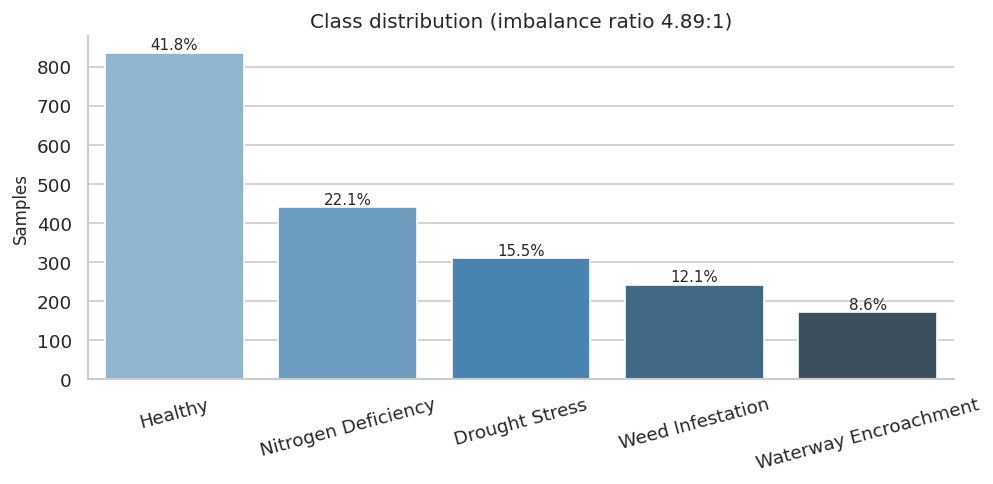

saved outputs/01_class_distribution.png
                class  count  percent
              Healthy    836    41.80
  Nitrogen Deficiency    441    22.05
       Drought Stress    310    15.50
     Weed Infestation    242    12.10
Waterway Encroachment    171     8.55
Majority class is Healthy at 41.8% of the sample. Macro F1, not accuracy, is the primary endpoint.


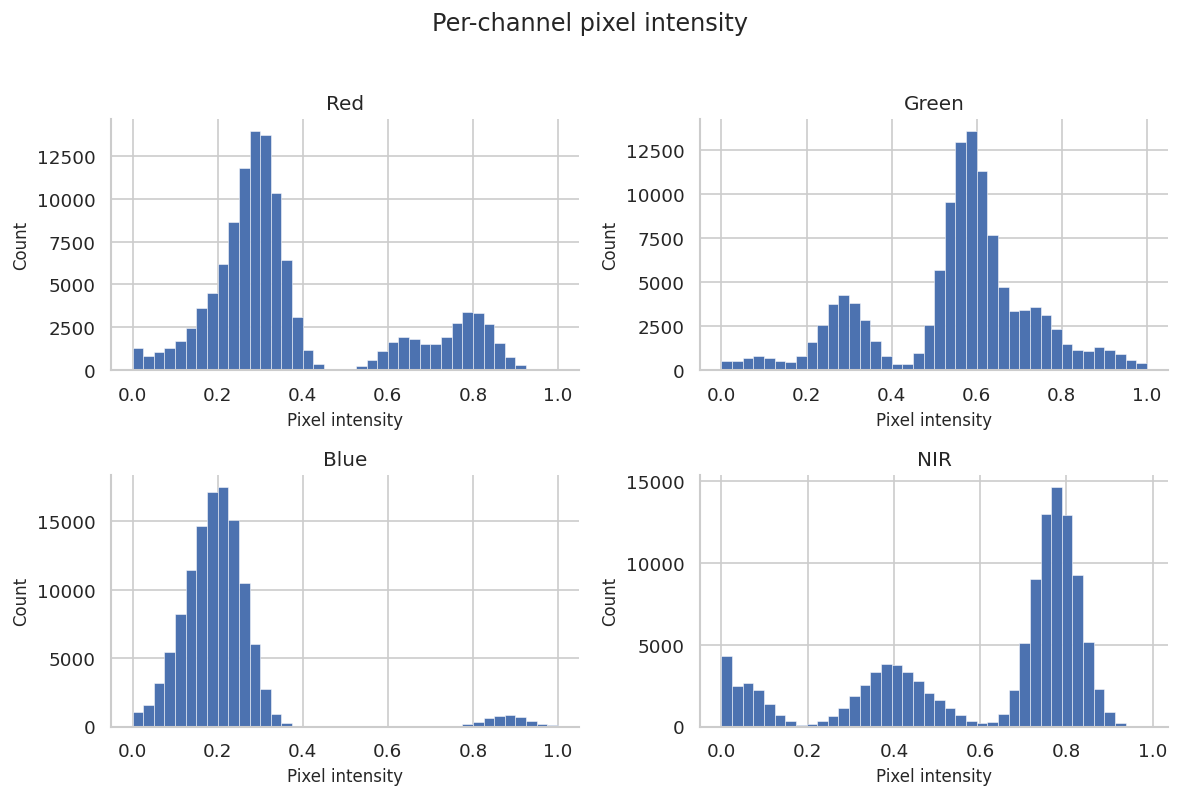

saved outputs/02_channel_histograms.png


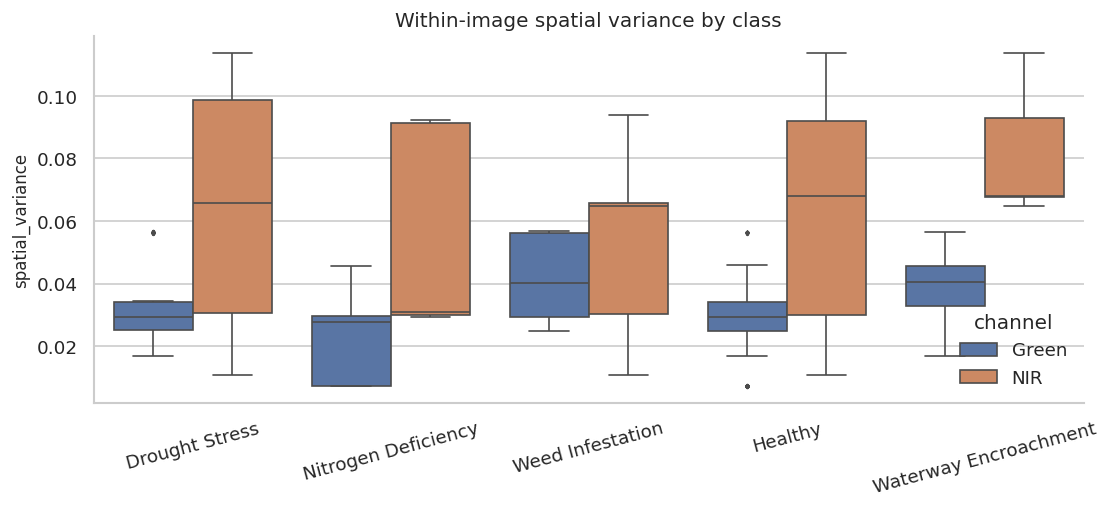

saved outputs/03_spatial_variance.png


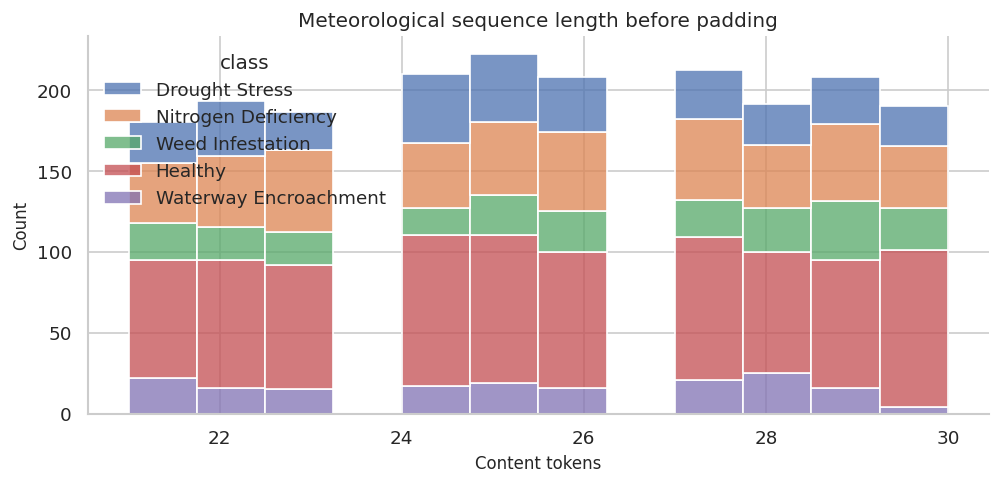

saved outputs/04_sequence_length.png
sequence length mean 25.6, min 21, max 30


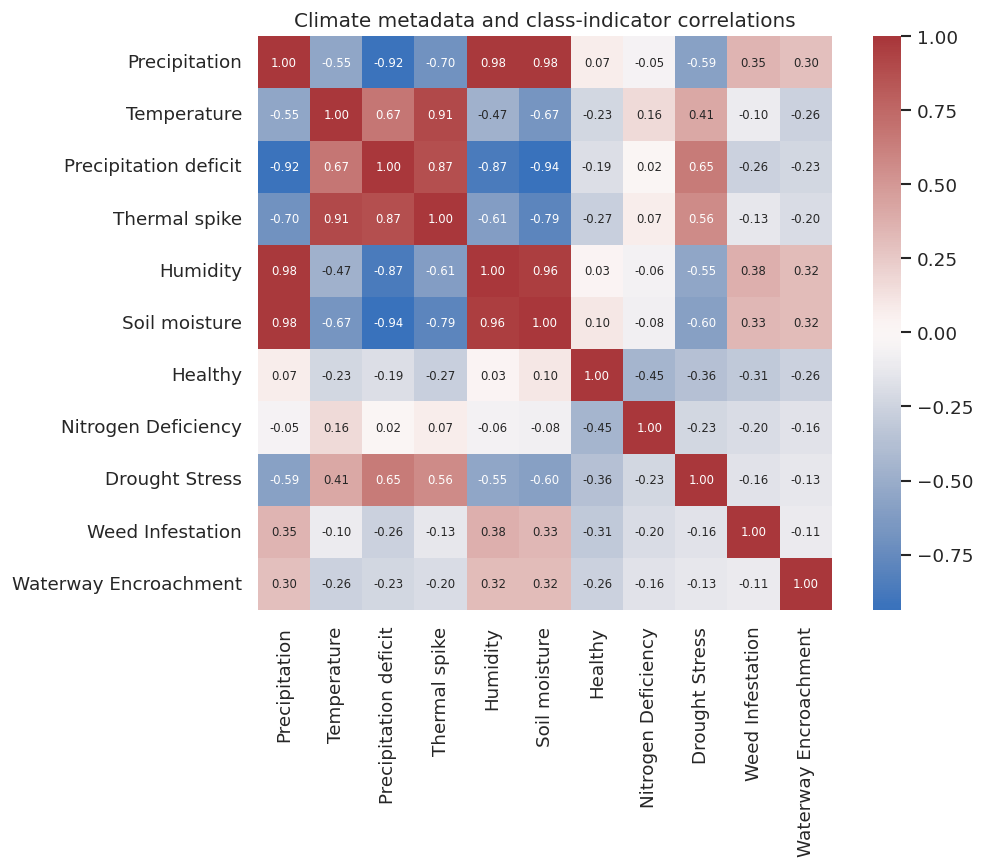

saved outputs/05_climate_correlation.png
Strongest |Pearson| links between climate metadata and class indicators:
              feature          class   pearson
Precipitation deficit Drought Stress  0.647407
        Soil moisture Drought Stress -0.595651
        Precipitation Drought Stress -0.588424
        Thermal spike Drought Stress  0.563399
             Humidity Drought Stress -0.549873
          Temperature Drought Stress  0.414554
These scalars are exploratory metadata. The networks receive token ids, not this table.


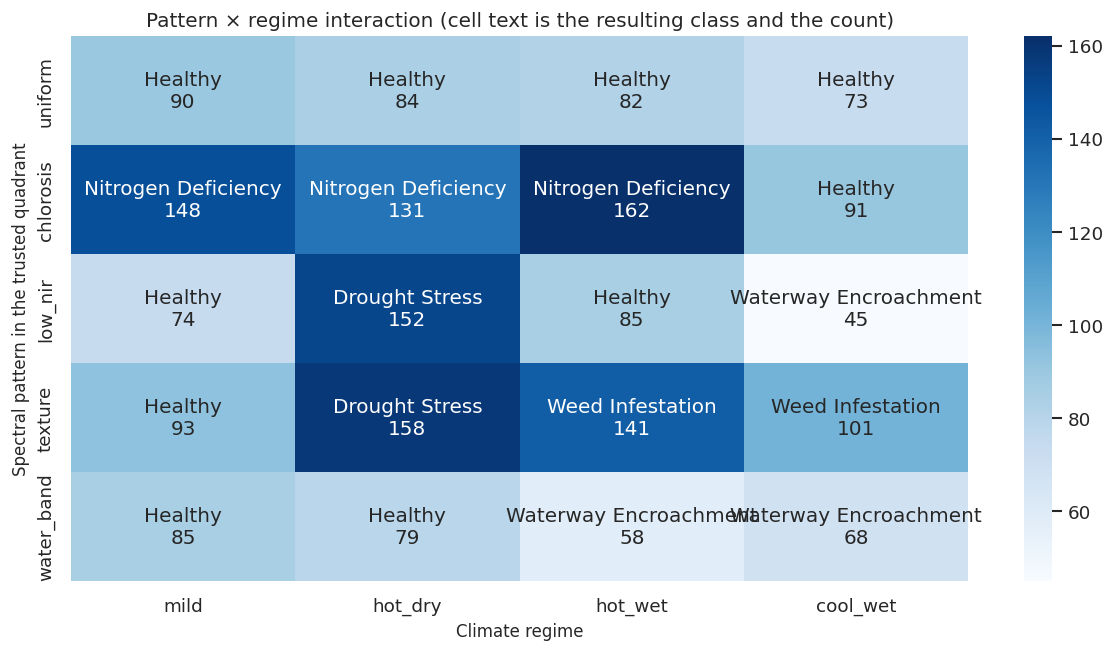

saved outputs/06_interaction_map.png
Reading the map: low_nir under hot_dry is Drought Stress, while the same low_nir pattern under cool_wet is Waterway Encroachment. A spectrum-only classifier cannot separate those cells.

Mean spectral intensity by class


,Red,Green,Blue,NIR
class,,,,
Drought Stress,0.353,0.525,0.212,0.589
Nitrogen Deficiency,0.430,0.582,0.205,0.597
Weed Infestation,0.316,0.553,0.197,0.635
Healthy,0.383,0.549,0.215,0.600
Waterway Encroachment,0.324,0.497,0.242,0.573



Example decoded sequences (padding omitted)
  Healthy: MARKER MARKER MARKER MARKER MARKER SOIL_HIGH PRECIP_MED TEMP_MED TEMP_MED HUM_LOW PRECIP_MED TEMP_MED TEMP_MED TEMP_MED HUM_LOW PRECIP_MED TEMP_MED PRECIP_MED ...
  Nitrogen Deficiency: MARKER MARKER MARKER MARKER MARKER PRECIP_LOW PRECIP_LOW PRECIP_LOW TEMP_HIGH SOIL_LOW TEMP_HIGH PRECIP_LOW TEMP_HIGH PRECIP_LOW PRECIP_LOW PRECIP_LOW HUM_LOW TEMP_HIGH ...
  Drought Stress: PRECIP_LOW TEMP_HIGH PRECIP_LOW SOIL_LOW TEMP_HIGH SOIL_LOW PRECIP_LOW SOIL_LOW TEMP_HIGH SOIL_LOW PRECIP_LOW TEMP_HIGH PRECIP_LOW HUM_LOW TEMP_HIGH PRECIP_LOW TEMP_HIGH TEMP_HIGH ...
  Weed Infestation: PRECIP_HIGH SOIL_HIGH TEMP_HIGH HUM_HIGH PRECIP_HIGH TEMP_HIGH PRECIP_HIGH MARKER MARKER MARKER MARKER MARKER TEMP_HIGH SOIL_HIGH PRECIP_HIGH PRECIP_HIGH TEMP_HIGH PRECIP_HIGH ...
  Waterway Encroachment: TEMP_HIGH HUM_HIGH SOIL_HIGH PRECIP_HIGH PRECIP_HIGH TEMP_HIGH HUM_HIGH HUM_HIGH TEMP_HIGH SOIL_HIGH HUM_HIGH SOIL_HIGH PRECIP_HIGH TEMP_HIGH MARKER MARKER MA

In [4]:
"""Exploratory plots: imbalance, spectra, spatial variance, sequence length, climate correlation."""
def save_show(fig: plt.Figure, filename: str) -> Path:
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    print(f"saved {path}")
    return path


def plot_class_distribution(labels: np.ndarray) -> None:
    counts = np.bincount(labels, minlength=len(CLASS_NAMES))
    frame = pd.DataFrame({"class": CLASS_NAMES, "count": counts, "percent": 100.0 * counts / counts.sum()})
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    sns.barplot(data=frame, x="class", y="count", hue="class", palette="Blues_d", legend=False, ax=ax)
    for patch, percent in zip(ax.patches, frame["percent"]):
        ax.text(patch.get_x() + patch.get_width() / 2, patch.get_height(), f"{percent:.1f}%", ha="center", va="bottom", fontsize=9)
    ratio = float(counts.max() / max(int(counts.min()), 1))
    ax.set_title(f"Class distribution (imbalance ratio {ratio:.2f}:1)")
    ax.set_xlabel("")
    ax.set_ylabel("Samples")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()
    save_show(fig, "01_class_distribution.png")
    print(frame.to_string(index=False))
    print(
        f"Majority class is {CLASS_NAMES[int(counts.argmax())]} at {100 * counts.max() / counts.sum():.1f}% "
        f"of the sample. Macro F1, not accuracy, is the primary endpoint."
    )


def plot_channel_histograms(images: np.ndarray, max_pixels: int = 120_000) -> None:
    rng = np.random.default_rng(CFG.SEED)
    channel_names = ("Red", "Green", "Blue", "NIR")
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
    flat = images.reshape(images.shape[0], images.shape[1], -1)
    for channel, axis in enumerate(axes.ravel()):
        values = flat[:, channel, :].reshape(-1)
        if values.size > max_pixels:
            values = values[rng.choice(values.size, size=max_pixels, replace=False)]
        axis.hist(values, bins=40, color="#4C72B0", edgecolor="white", linewidth=0.3)
        axis.set_title(channel_names[channel])
        axis.set_xlabel("Pixel intensity")
        axis.set_ylabel("Count")
    fig.suptitle("Per-channel pixel intensity", y=1.02)
    fig.tight_layout()
    save_show(fig, "02_channel_histograms.png")


def plot_spatial_variance(images: np.ndarray, labels: np.ndarray) -> None:
    variance = images.var(axis=(2, 3))
    frame = pd.DataFrame(variance, columns=("Red", "Green", "Blue", "NIR"))
    frame["class"] = [CLASS_NAMES[int(label)] for label in labels]
    melted = frame.melt(id_vars="class", value_vars=("Green", "NIR"), var_name="channel", value_name="spatial_variance")
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    sns.boxplot(data=melted, x="class", y="spatial_variance", hue="channel", ax=ax, fliersize=1)
    ax.set_title("Within-image spatial variance by class")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()
    save_show(fig, "03_spatial_variance.png")


def plot_sequence_lengths(lengths: np.ndarray, labels: np.ndarray) -> None:
    frame = pd.DataFrame({"length": lengths, "class": [CLASS_NAMES[int(label)] for label in labels]})
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    sns.histplot(data=frame, x="length", hue="class", multiple="stack", bins=12, ax=ax)
    ax.set_title("Meteorological sequence length before padding")
    ax.set_xlabel("Content tokens")
    fig.tight_layout()
    save_show(fig, "04_sequence_length.png")
    print(f"sequence length mean {lengths.mean():.1f}, min {lengths.min()}, max {lengths.max()}")


def plot_climate_correlation(climate: np.ndarray, labels: np.ndarray) -> None:
    frame = pd.DataFrame(climate, columns=CLIMATE_COLUMNS)
    for class_id, name in enumerate(CLASS_NAMES):
        frame[name] = (labels == class_id).astype(np.float32)
    corr = frame.corr(method="pearson")
    fig, ax = plt.subplots(figsize=(9.2, 7.4))
    sns.heatmap(corr, cmap="vlag", center=0.0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, square=True)
    ax.set_title("Climate metadata and class-indicator correlations")
    fig.tight_layout()
    save_show(fig, "05_climate_correlation.png")
    focus = corr.loc[list(CLIMATE_COLUMNS), list(CLASS_NAMES)]
    stacked = focus.stack().rename("pearson").reset_index()
    stacked.columns = ("feature", "class", "pearson")
    strongest = stacked.reindex(stacked["pearson"].abs().sort_values(ascending=False).index).head(6)
    print("Strongest |Pearson| links between climate metadata and class indicators:")
    print(strongest.to_string(index=False))
    print("These scalars are exploratory metadata. The networks receive token ids, not this table.")


def plot_interaction_map(patterns: np.ndarray, regimes: np.ndarray) -> None:
    counts = np.zeros((len(PATTERNS), len(REGIMES)), dtype=np.int64)
    annotations = np.empty(counts.shape, dtype=object)
    for row, pattern in enumerate(PATTERNS):
        for col, regime in enumerate(REGIMES):
            counts[row, col] = int(np.sum((patterns == pattern) & (regimes == regime)))
            annotations[row, col] = f"{CLASS_NAMES[LABEL_OF[(pattern, regime)]]}\n{counts[row, col]}"
    fig, ax = plt.subplots(figsize=(10.2, 5.6))
    sns.heatmap(counts, annot=annotations, fmt="", cmap="Blues", xticklabels=REGIMES, yticklabels=PATTERNS, ax=ax)
    ax.set_title("Pattern × regime interaction (cell text is the resulting class and the count)")
    ax.set_xlabel("Climate regime")
    ax.set_ylabel("Spectral pattern in the trusted quadrant")
    fig.tight_layout()
    save_show(fig, "06_interaction_map.png")
    print(
        "Reading the map: low_nir under hot_dry is Drought Stress, while the same low_nir "
        "pattern under cool_wet is Waterway Encroachment. A spectrum-only classifier cannot separate those cells."
    )


plot_class_distribution(BUNDLE.labels)
plot_channel_histograms(BUNDLE.images)
plot_spatial_variance(BUNDLE.images, BUNDLE.labels)
plot_sequence_lengths(BUNDLE.lengths, BUNDLE.labels)
plot_climate_correlation(BUNDLE.climate, BUNDLE.labels)
if BUNDLE.patterns is not None and BUNDLE.regimes is not None:
    plot_interaction_map(BUNDLE.patterns, BUNDLE.regimes)
else:
    print("Interaction map skipped: real data has no generator pattern/regime fields.")

means = pd.DataFrame(BUNDLE.images.mean(axis=(2, 3)), columns=("Red", "Green", "Blue", "NIR"))
means["class"] = [CLASS_NAMES[int(label)] for label in BUNDLE.labels]
print("\nMean spectral intensity by class")
display(means.groupby("class", sort=False).mean().round(3))

preview_ids = [int(np.where(BUNDLE.labels == class_id)[0][0]) for class_id in range(CFG.num_classes)]
print("\nExample decoded sequences (padding omitted)")
for sample_id in preview_ids:
    content = [TOKEN_NAMES[int(token)] for token in BUNDLE.tokens[sample_id] if int(token) != PAD]
    print(f"  {CLASS_NAMES[int(BUNDLE.labels[sample_id])]}: {' '.join(content[:18])} ...")

## 2. Architectures built from scratch

Every trainable layer below is an `nn.Conv2d`, `nn.Linear`, `nn.LSTM`, `nn.Embedding`, normalization, or dropout. There is no pretrained backbone, no `torchvision.models` factory, and no high-level multimodal wrapper. The same training harness calls every model with `(images, tokens)` so the linguistic tensor is available even to the unimodal CNN, which is required to ignore it.

### Why this shape, and what it costs

A translation-equivariant convolution produces a feature at location `(i, j)` that does not know it is at `(i, j)`. The marker burst names a coordinate, not a color. The spatial query therefore adds an explicit coordinate projection, \(W_p[x, y]\), to the visual projection \(W_q F_v\). Without that term, a shared linear map cannot implement "look at the quadrant the sequence nominates." Liu et al. (2018) showed the same failure mode for ordinary convolutions on coordinate-sensitive tasks. The coordinate term is an inductive bias, not a label leak: the quadrant index is never an input.

The score matrix is the specified product \(QK^\top / \sqrt{d}\). Softmax is taken over **spatial sites**, not over time. A softmax over time would write a context vector at every location and would never choose a region. The mask \(m\) is a distribution over the pooled grid. Its values are the gated visual features, because the quantity to read is the spectrum at the nominated place. Copying temporal states into the visual grid, as a generic multimodal transformer does, would not answer that question.

Two gates sit on top of the mask.

- A temporal gate selects which days carry the location code. Averaging every day equally lets ordinary weather tokens dilute the marker burst. The gate score is \(w_\alpha^\top F_t + w_e^\top e_t\): the recurrent state plus a residual on the token embedding itself. The residual matters for optimization. A randomly initialized LSTM does not make the marker linearly separable in \(F_t\) on every seed, and the climate summary is then an easier local minimum. The embedding residual can upweight the marker symbol in a few steps, after which the keys at those steps — which still carry absolute time — address the grid. It is not a label feature. Every quadrant uses the same marker id.
- A channel gate \(g = \sigma(W_g \bar F_t)\) rescales visual channels from the pooled climate state. It is the FiLM / squeeze-and-excitation idea (Perez et al., 2018; Hu et al., 2018) with the conditioning vector taken from the other modality. \(W_q\) is initialized at zero so the first epochs are a pure coordinate lookup. Gradients are free to move \(W_q\) away from zero once content should influence the address.

The backbone is intentionally shallow. A stem and three residual bottlenecks (1×1, 3×3, 1×1, GELU, projection shortcut when the shape changes) leave a receptive field of about 23 input pixels and a stride of 4. A deeper 3×3 stack on a 64-pixel tile mixes the distractor quadrant into every feature, and the attention mask then has nothing local left to read. The cost of the short stack is a smaller semantic receptive field. That trade is acceptable because the signatures in this study are regional intensity patterns, not fine object parts. Before the score matrix is formed, adaptive average pooling reduces the map to a fixed `attn_grid` (4×4). Each quadrant then occupies a 2×2 block, the attention matrix is \(O(R^2 T d)\) with \(R = 4\) rather than \(O(HW T)\), and sub-quadrant detail is aliased. Raising `attn_grid` is the knob if a future dataset needs a finer mask.

The temporal encoder is a two-layer BiLSTM with a learned token embedding and a learned absolute time embedding (Hochreiter and Schmidhuber, 1997; Graves and Schmidhuber, 2005). Thirty daily steps do not justify a temporal transformer. Recurrence is a better match to a short ordered log, and the time embedding makes the burst position linearly available to the hidden state. Forget-gate biases are initialized to 1 (Jozefowicz et al., 2015) so early memory updates are not shut off.

The head is the specified MLP: linear, layer norm, dropout, GELU, logits.

### What each baseline is allowed to compute

| Model | Visual path | Temporal path | Fusion | Interaction it cannot represent |
| --- | --- | --- | --- | --- |
| Unimodal CNN | Residual stack, global average pool, MLP | Ignored | None | Any climate distinction between identical spectra |
| Unimodal BiLSTM | Ignored | Embedding + BiLSTM, masked mean, MLP | None | Which quadrant is the true pattern |
| Early Fusion | Global mean and standard deviation | Mean token embedding, order discarded | Concatenation into an MLP | Marker position; the critical swap pairs are identical inputs |
| Late Fusion | Residual stack and its own MLP logits | BiLSTM and its own MLP logits | Input-independent softmax weights | A cross-term between place and pattern |
| ST-CGN | Residual map, coordinate query, gated readout | BiLSTM keys and temporal gate | Spatial mask plus channel gate | Sub-grid detail below `attn_grid`, and a missing log (the readout falls back to the climate summary) |

Late fusion contains two competent unimodal classifiers. Its weakness is the fusion operator, a pair of learned scalars, not a starved encoder. Early fusion's MLP is the same head used elsewhere. Its weakness is the pooling, which deletes order. Those choices follow the early / late taxonomy in Baltrušaitis, Ahuja, and Morency (2019) rather than a weakened control.

In [5]:
"""From-scratch residual CNN, BiLSTM, cross-modal gated attention, ST-CGN, and four baselines."""
def receptive_field_pixels() -> int:
    """Backbone receptive field in input pixels for the stack defined below.

    Stem 3x3 stride 2 yields RF 3 and jump 2.
    The stride-2 bottleneck yields RF 7 and jump 4.
    Each later stride-1 3x3 adds ``2 * jump``: RF 15, then RF 23.
    """
    return 23


def init_module(module: nn.Module) -> None:
    """Kaiming convolutions, Xavier linear maps, small embeddings, open LSTM forget gates."""
    for child in module.modules():
        if isinstance(child, nn.Conv2d):
            nn.init.kaiming_normal_(child.weight, nonlinearity="relu")
        elif isinstance(child, nn.Linear):
            nn.init.xavier_uniform_(child.weight)
            if child.bias is not None:
                nn.init.zeros_(child.bias)
        elif isinstance(child, nn.Embedding):
            nn.init.normal_(child.weight, mean=0.0, std=0.02)
            if child.padding_idx is not None:
                with torch.no_grad():
                    child.weight[child.padding_idx].zero_()
    for name, parameter in module.named_parameters():
        if "lstm" in name and "weight_hh" in name:
            nn.init.orthogonal_(parameter)
        elif "lstm" in name and "weight_ih" in name:
            nn.init.xavier_uniform_(parameter)
        elif "lstm" in name and "bias" in name:
            nn.init.zeros_(parameter)
            quarter = parameter.numel() // 4
            parameter.data[quarter : 2 * quarter].fill_(1.0)


def masked_mean(sequence: torch.Tensor, tokens: torch.Tensor, pad_idx: int = PAD) -> torch.Tensor:
    """Mean over valid time steps. An all-pad row returns the zero vector, not NaN."""
    valid = tokens.ne(pad_idx).unsqueeze(-1).to(sequence.dtype)
    return (sequence * valid).sum(dim=1) / valid.sum(dim=1).clamp(min=1.0)


class ResidualBottleneckBlock(nn.Module):
    """1x1, 3x3, 1x1 bottleneck with BatchNorm, GELU, and a projection shortcut."""

    def __init__(self, in_channels: int, out_channels: int, stride: int = 1) -> None:
        super().__init__()
        mid = max(out_channels // 2, 8)
        self.conv1 = nn.Conv2d(in_channels, mid, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.conv2 = nn.Conv2d(mid, mid, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(mid)
        self.conv3 = nn.Conv2d(mid, out_channels, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(out_channels)
        self.act = nn.GELU()
        if stride != 1 or in_channels != out_channels:
            self.skip = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.skip = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.skip(x)
        hidden = self.act(self.bn1(self.conv1(x)))
        hidden = self.act(self.bn2(self.conv2(hidden)))
        hidden = self.bn3(self.conv3(hidden))
        return self.act(hidden + residual)


class CustomCNNBackbone(nn.Module):
    """Stem plus three residual bottlenecks. Spatial stride is 4 and the field is local."""

    def __init__(self, in_channels: int, channels: tuple[int, int, int]) -> None:
        super().__init__()
        c1, c2, c3 = channels
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, c1, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(c1),
            nn.GELU(),
        )
        self.stage = nn.Sequential(
            ResidualBottleneckBlock(c1, c2, stride=2),
            ResidualBottleneckBlock(c2, c3, stride=1),
            ResidualBottleneckBlock(c3, c3, stride=1),
        )
        self.out_channels = c3

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.stage(self.stem(images))


class CustomBiLSTMEncoder(nn.Module):
    """Token embedding, absolute time embedding, and a packed bidirectional LSTM."""

    def __init__(self, vocab_size: int, embed_dim: int, hidden_size: int, num_layers: int, dropout: float, max_len: int, pad_idx: int) -> None:
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.time_embedding = nn.Embedding(max_len, embed_dim)
        self.embed_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.norm = nn.LayerNorm(hidden_size * 2)
        self.out_dim = hidden_size * 2

    def forward(self, tokens: torch.Tensor) -> torch.Tensor:
        batch, steps = tokens.shape
        if steps > self.time_embedding.num_embeddings:
            raise ValueError(f"Sequence length {steps} exceeds the time embedding ({self.time_embedding.num_embeddings}).")
        positions = torch.arange(steps, device=tokens.device)
        token_embed = self.embedding(tokens)
        token_embed = token_embed * tokens.ne(self.pad_idx).unsqueeze(-1).to(token_embed.dtype)
        embeddings = token_embed + self.time_embedding(positions)[None, :, :]
        embeddings = embeddings * tokens.ne(self.pad_idx).unsqueeze(-1).to(embeddings.dtype)
        dropped = self.embed_dropout(embeddings)
        lengths = tokens.ne(self.pad_idx).sum(dim=1).clamp(min=1).detach().cpu()
        packed = nn.utils.rnn.pack_padded_sequence(dropped, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        sequence, _ = nn.utils.rnn.pad_packed_sequence(packed_out, batch_first=True, total_length=steps)
        return self.norm(sequence), token_embed


class ClassificationHead(nn.Module):
    """Linear -> LayerNorm -> Dropout -> GELU -> logits."""

    def __init__(self, in_dim: int, hidden_dim: int, num_classes: int, dropout: float) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.Dropout(dropout),
            nn.GELU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        return self.net(features)


class CrossModalGatedAttention(nn.Module):
    """Climate-addressed spatial mask with a temporal gate and a channel gate.

    Shapes
    ------
    visual:  (B, C, H, W) -> pooled to (B, C, R, R)
    temporal: (B, T, D)
    mask: (B, 1, R, R), a distribution over the grid
    readout: (B, 2 * attn_dim)
    """

    def __init__(self, visual_channels: int, temporal_dim: int, embed_dim: int, attn_dim: int, grid: int, dropout: float) -> None:
        super().__init__()
        self.grid = grid
        self.attn_dim = attn_dim
        self.query = nn.Linear(visual_channels, attn_dim)
        self.key = nn.Linear(temporal_dim, attn_dim)
        self.position = nn.Linear(2, attn_dim)
        self.time_gate = nn.Linear(temporal_dim, 1)
        self.token_time_gate = nn.Linear(embed_dim, 1)
        self.channel_gate = nn.Linear(temporal_dim, visual_channels)
        self.visual_out = nn.Linear(visual_channels, attn_dim)
        self.context_out = nn.Linear(temporal_dim, attn_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, visual: torch.Tensor, temporal: torch.Tensor, token_embeddings: torch.Tensor, tokens: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        visual = nn.functional.adaptive_avg_pool2d(visual, (self.grid, self.grid))
        batch, channels, height, width = visual.shape
        sites = visual.flatten(2).transpose(1, 2)
        valid = tokens.ne(PAD)
        climate = masked_mean(temporal, tokens)
        gate = torch.sigmoid(self.channel_gate(climate))
        gated_sites = sites * gate.unsqueeze(1)

        y_axis = torch.linspace(-1.0, 1.0, height, device=visual.device)
        x_axis = torch.linspace(-1.0, 1.0, width, device=visual.device)
        grid_y, grid_x = torch.meshgrid(y_axis, x_axis, indexing="ij")
        coordinates = torch.stack((grid_x, grid_y), dim=-1).reshape(1, height * width, 2)
        # Q = W_q F_v + W_p [x, y], K = W_k F_t. W_q is zero at initialization.
        query = self.query(sites) + self.position(coordinates)
        key = self.key(temporal)
        scores = torch.matmul(query, key.transpose(-1, -2)) / math.sqrt(self.attn_dim)
        scores = scores.masked_fill(~valid.unsqueeze(1), -50.0).clamp(-50.0, 50.0)
        spatial_per_time = torch.softmax(scores, dim=1)

        time_logits = self.time_gate(temporal).squeeze(-1) + self.token_time_gate(token_embeddings).squeeze(-1)
        time_logits = time_logits.masked_fill(~valid, torch.finfo(time_logits.dtype).min)
        alpha = torch.nan_to_num(torch.softmax(time_logits, dim=-1), nan=0.0)
        mask = torch.matmul(spatial_per_time, alpha.unsqueeze(-1)).squeeze(-1)
        readout = torch.matmul(mask.unsqueeze(1), gated_sites).squeeze(1)
        missing = ~valid.any(dim=1)
        readout = readout.masked_fill(missing.unsqueeze(-1), 0.0)
        fused = self.dropout(torch.cat((self.visual_out(readout), self.context_out(climate)), dim=-1))
        return fused, mask.view(batch, 1, height, width), gate


class ST_CGN_Model(nn.Module):
    """Spatial residual map, bidirectional climate encoder, gated cross-modal readout."""

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.backbone = CustomCNNBackbone(cfg.in_channels, cfg.cnn_channels)
        self.encoder = CustomBiLSTMEncoder(
            cfg.vocab_size, cfg.embed_dim, cfg.lstm_hidden, cfg.lstm_layers, cfg.dropout, cfg.seq_len, cfg.pad_idx
        )
        self.fusion = CrossModalGatedAttention(
            self.backbone.out_channels, self.encoder.out_dim, cfg.embed_dim, cfg.attn_dim, cfg.attn_grid, cfg.dropout
        )
        self.head = ClassificationHead(cfg.attn_dim * 2, cfg.head_dim, cfg.num_classes, cfg.dropout)
        init_module(self)
        nn.init.zeros_(self.fusion.query.weight)
        nn.init.zeros_(self.fusion.query.bias)

    def forward(self, images: torch.Tensor, tokens: torch.Tensor, return_aux: bool = False):
        visual = self.backbone(images)
        temporal, token_embeddings = self.encoder(tokens)
        fused, mask, gate = self.fusion(visual, temporal, token_embeddings, tokens)
        logits = self.head(fused)
        if return_aux:
            return logits, {"spatial_attention": mask, "channel_gate": gate}
        return logits


class UnimodalCNN(nn.Module):
    """Visual residual stack and global average pooling. Tokens are accepted and ignored."""

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.backbone = CustomCNNBackbone(cfg.in_channels, cfg.cnn_channels)
        self.head = ClassificationHead(self.backbone.out_channels, cfg.head_dim, cfg.num_classes, cfg.dropout)
        init_module(self)

    def forward(self, images: torch.Tensor, tokens: torch.Tensor, return_aux: bool = False):
        del tokens, return_aux
        pooled = self.backbone(images).mean(dim=(2, 3))
        return self.head(pooled)


class UnimodalBiLSTM(nn.Module):
    """Meteorological BiLSTM and masked mean pooling. The image is accepted and ignored."""

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.encoder = CustomBiLSTMEncoder(
            cfg.vocab_size, cfg.embed_dim, cfg.lstm_hidden, cfg.lstm_layers, cfg.dropout, cfg.seq_len, cfg.pad_idx
        )
        self.head = ClassificationHead(self.encoder.out_dim, cfg.head_dim, cfg.num_classes, cfg.dropout)
        init_module(self)

    def forward(self, images: torch.Tensor, tokens: torch.Tensor, return_aux: bool = False):
        del images, return_aux
        sequence, _embeddings = self.encoder(tokens)
        return self.head(masked_mean(sequence, tokens))


class EarlyFusionNet(nn.Module):
    """Orderless early fusion: image moments concatenated with the mean token embedding."""

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.embedding = nn.Embedding(cfg.vocab_size, cfg.embed_dim, padding_idx=cfg.pad_idx)
        self.visual_proj = nn.Linear(cfg.in_channels * 2, cfg.attn_dim)
        self.text_proj = nn.Linear(cfg.embed_dim, cfg.attn_dim)
        self.head = ClassificationHead(cfg.attn_dim * 2, cfg.head_dim, cfg.num_classes, cfg.dropout)
        init_module(self)

    def forward(self, images: torch.Tensor, tokens: torch.Tensor, return_aux: bool = False):
        del return_aux
        moments = torch.cat((images.mean(dim=(2, 3)), images.std(dim=(2, 3))), dim=-1)
        text = masked_mean(self.embedding(tokens), tokens)
        return self.head(torch.cat((self.visual_proj(moments), self.text_proj(text)), dim=-1))


class LateFusionNet(nn.Module):
    """Independent unimodal heads whose logit vectors are mixed by learned softmax weights.

    The weights do not depend on the sample. The fusion is an affine combination of
    decisions and cannot form a product between a spatial site and a temporal state.
    """

    def __init__(self, cfg: Config) -> None:
        super().__init__()
        self.backbone = CustomCNNBackbone(cfg.in_channels, cfg.cnn_channels)
        self.encoder = CustomBiLSTMEncoder(
            cfg.vocab_size, cfg.embed_dim, cfg.lstm_hidden, cfg.lstm_layers, cfg.dropout, cfg.seq_len, cfg.pad_idx
        )
        self.visual_head = ClassificationHead(self.backbone.out_channels, cfg.head_dim, cfg.num_classes, cfg.dropout)
        self.text_head = ClassificationHead(self.encoder.out_dim, cfg.head_dim, cfg.num_classes, cfg.dropout)
        self.fusion_weight = nn.Parameter(torch.zeros(2))
        init_module(self)

    def forward(self, images: torch.Tensor, tokens: torch.Tensor, return_aux: bool = False):
        del return_aux
        visual_logits = self.visual_head(self.backbone(images).mean(dim=(2, 3)))
        sequence, _embeddings = self.encoder(tokens)
        text_logits = self.text_head(masked_mean(sequence, tokens))
        weights = torch.softmax(self.fusion_weight, dim=0)
        return weights[0] * visual_logits + weights[1] * text_logits


def build_model(name: str, cfg: Config) -> nn.Module:
    builders = {
        "ST-CGN": ST_CGN_Model,
        "Unimodal CNN": UnimodalCNN,
        "Unimodal BiLSTM": UnimodalBiLSTM,
        "Early Fusion": EarlyFusionNet,
        "Late Fusion": LateFusionNet,
    }
    if name not in builders:
        raise KeyError(name)
    return builders[name](cfg)


def count_parameters(model: nn.Module) -> int:
    return int(sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))

In [6]:
"""Fail fast: shapes, missing logs, order invariance, attention normalization, backward."""
def _check(name: str, condition: bool) -> None:
    status = "PASS" if condition else "FAIL"
    print(f"[{status}] {name}")
    if not condition:
        raise AssertionError(name)


def run_self_checks(cfg: Config, device: torch.device) -> None:
    generator = torch.Generator().manual_seed(cfg.SEED)
    images = torch.randn(4, cfg.in_channels, cfg.image_size, cfg.image_size, generator=generator)
    tokens = torch.randint(1, cfg.vocab_size, (4, cfg.seq_len), generator=generator)
    tokens[0, cfg.seq_len // 2 :] = PAD
    tokens[1] = PAD
    images = images.to(device)
    tokens = tokens.to(device)
    labels = torch.zeros(4, dtype=torch.long, device=device)

    for name in MODEL_ORDER:
        model = build_model(name, cfg).to(device)
        model.train()
        logits = model(images, tokens)
        _check(f"{name} logits {(tuple(logits.shape))}", tuple(logits.shape) == (4, cfg.num_classes))
        loss = nn.functional.cross_entropy(logits, labels)
        loss.backward()
        grads = [parameter.grad for parameter in model.parameters() if parameter.requires_grad and parameter.grad is not None]
        _check(f"{name} finite loss and gradients", bool(torch.isfinite(loss).item()) and all(torch.isfinite(item).all() for item in grads))
        if name == "ST-CGN":
            _check("backbone stride reduces H and W by 4", model.backbone(images[:1]).shape[-1] == cfg.image_size // 4)
            model.eval()
            with torch.no_grad():
                _, aux = model(images[:1], tokens[:1], return_aux=True)
            mask = aux["spatial_attention"]
            _check("attention grid matches attn_grid", tuple(mask.shape[-2:]) == (cfg.attn_grid, cfg.attn_grid))
            mass = mask.detach().flatten(1).sum(dim=1)
            _check("spatial mask is a probability distribution", bool(torch.allclose(mass, torch.ones_like(mass), atol=1e-4)))
            gate = aux["channel_gate"]
            _check("channel gate lies in (0, 1)", bool(torch.all(gate > 0).item() and torch.all(gate < 1).item()))
        del model
        release_memory()

    early = build_model("Early Fusion", cfg).to(device).eval()
    same_image = images[:1]
    order_a = torch.tensor([[MARKER, MARKER, MARKER, TEMP_HIGH, TEMP_HIGH, PRECIP_LOW, PRECIP_LOW] + [PAD] * (cfg.seq_len - 7)], device=device)
    order_b = torch.tensor([[TEMP_HIGH, TEMP_HIGH, PRECIP_LOW, PRECIP_LOW, MARKER, MARKER, MARKER] + [PAD] * (cfg.seq_len - 7)], device=device)
    with torch.no_grad():
        logits_a = early(same_image, order_a)
        logits_b = early(same_image, order_b)
    _check("early fusion is invariant to token order", bool(torch.allclose(logits_a, logits_b, atol=1e-5)))

    encoder = CustomBiLSTMEncoder(cfg.vocab_size, cfg.embed_dim, cfg.lstm_hidden, cfg.lstm_layers, cfg.dropout, cfg.seq_len, cfg.pad_idx).to(device).eval()
    with torch.no_grad():
        hidden_a, _ = encoder(order_a)
        hidden_b, _ = encoder(order_b)
    _check("BiLSTM hidden states depend on token order", not bool(torch.allclose(hidden_a, hidden_b, atol=1e-4)))
    del early, encoder
    release_memory()
    print(f"receptive field of the residual stack: {receptive_field_pixels()} input pixels")


run_self_checks(CFG, DEVICE)

[PASS] ST-CGN logits (4, 5)
[PASS] ST-CGN finite loss and gradients
[PASS] backbone stride reduces H and W by 4
[PASS] attention grid matches attn_grid
[PASS] spatial mask is a probability distribution
[PASS] channel gate lies in (0, 1)
[PASS] Unimodal CNN logits (4, 5)
[PASS] Unimodal CNN finite loss and gradients
[PASS] Unimodal BiLSTM logits (4, 5)
[PASS] Unimodal BiLSTM finite loss and gradients
[PASS] Early Fusion logits (4, 5)
[PASS] Early Fusion finite loss and gradients
[PASS] Late Fusion logits (4, 5)
[PASS] Late Fusion finite loss and gradients
[PASS] early fusion is invariant to token order
[PASS] BiLSTM hidden states depend on token order
receptive field of the residual stack: 23 input pixels


## 3. Computational and algorithmic complexity

FLOPs below count one multiply and one add as two operations. Batch normalization, layer normalization, softmax, and embedding lookups are omitted; on this stack they are a small fraction of the convolution and recurrent terms. The attention products \(QK^\top\) and \(m^\top \tilde F_v\) are not `nn.Linear` modules, so the profiler adds them from the grid size, the sequence length, and the channel width. Figures are for one sample with a fully valid sequence. Training memory is larger: AdamW keeps two extra states, about 12 bytes per parameter in fp32, plus activations.

Let \(n\) be the image side, \(c\) the CNN width, \(t\) the sequence length, \(h\) the LSTM hidden size, \(d\) the attention width, and \(R\) the pooled attention grid. After the stride-4 backbone the native map is \(n/4 \times n/4\). Adaptive pooling replaces that map with \(R \times R\) before the score matrix exists.

| Term | Time | Activation memory | Where it is paid |
| --- | --- | --- | --- |
| Residual CNN | \(O(c^2 n^2)\) | \(O(c n^2)\) | Every model with a visual stack |
| BiLSTM | \(O(t h (e + h))\) | \(O(t h)\) | ST-CGN, BiLSTM, late fusion |
| Score matrix before pooling | \(O((n/4)^2 t d)\) | \(O((n/4)^2 t)\) | Avoided |
| Score matrix after pooling | \(O(R^2 t d)\) | \(O(R^2 t)\) | ST-CGN only |
| Early fusion | \(O(c_{\mathrm{in}} n^2 + t e)\) | \(O(d)\) | Moments and a mean embedding |
| Late fusion | CNN + BiLSTM | sum of the two | No cross-term, no \(R^2 t\) map |

With \(R = 4\) and \(t = 30\), the mask is 16 by 30 scores per sample. That is the concrete form of the \(O(H W T)\) concern: the product is taken on the pooled grid, not on the raw 128×128 lattice. Removing the pool, or setting \(R = n\), restores a quadratic spatial blow-up and is the change most likely to exhaust GPU memory. The batch dimension multiplies every term.

### Numerical, memory, and data edge cases

- **Softmax scale.** Scores are divided by \(\sqrt{d}\) and clamped to \([-50, 50]\). Padded steps are filled with \(-50\) before the spatial softmax. An all-pad row makes the temporal softmax undefined; those outputs are replaced with zeros and the visual readout is set to 0, so a missing log cannot produce NaN. The head then sees only the zero climate summary plus its own bias.
- **CUDA memory.** The failure mode is the attention map \(B \times R^2 \times T\) together with CNN activations, not the parameter count. The training loop catches an out-of-memory error, clears the cache, and tells you to lower `batch_size` or `image_size`.
- **BatchNorm and a batch of one.** Training drops the last incomplete batch only when the fold is at least two batches long, so a singleton batch does not update BatchNorm. Evaluation still scores every validation sample.
- **Class absence.** Stratified folds require at least five samples in every class. The loader raises a named error instead of silently emitting an undefined macro F1.
- **Internal gaps in a weather log.** Content is left-aligned. That preserves a usable sequence and destroys absolute timing. A production logger should emit an explicit missing-day token rather than a pad in the middle.
- **Receptive field versus grid.** The 23-pixel field is local on a 128-pixel tile and only marginally local on a 64-pixel debug tile. A deeper stack would raise accuracy on fine textures and erase the quadrant signal this mask is asked to read.
- **Initialization of \(W_q\).** Starting at zero is a coordinate-lookup bias. It is not a constraint: the weights receive gradients. The corresponding cost is that a dataset whose address depends on appearance rather than on a time code may need more epochs to leave that initialization.
- **Determinism.** Seeds fix the split and the initial weights. TF32 and asynchronous GPU reductions can still move logits in the last bits on an A100. Metrics in this notebook are not claimed to be bitwise identical across GPU generations.

,model,parameters,flops,param_MiB_fp32,adamw_state_MiB,cross_check,time_complexity,memory_complexity
0,ST-CGN,"355,095","281,853,504",1.35,4.06,"thop macs=145,358,112","O(c^2 n^2 + t h^2 + R^2 t d), R=4",O(c n^2 + t h + R^2 t)
1,Unimodal CNN,"145,221","271,615,232",0.55,1.66,"thop macs=140,133,504",O(c^2 n^2),O(c n^2)
2,Unimodal BiLSTM,"177,381","9,372,928",0.68,2.03,"thop macs=4,825,216",O(t h (e + h)),O(t h)
3,Early Fusion,"21,701","41,216",0.08,0.25,"thop macs=21,120",O(n^2 + t e + d^2),O(d)
4,Late Fusion,"322,604","280,988,160",1.23,3.69,"thop macs=144,958,720",O(c^2 n^2 + t h^2),O(c n^2 + t h)


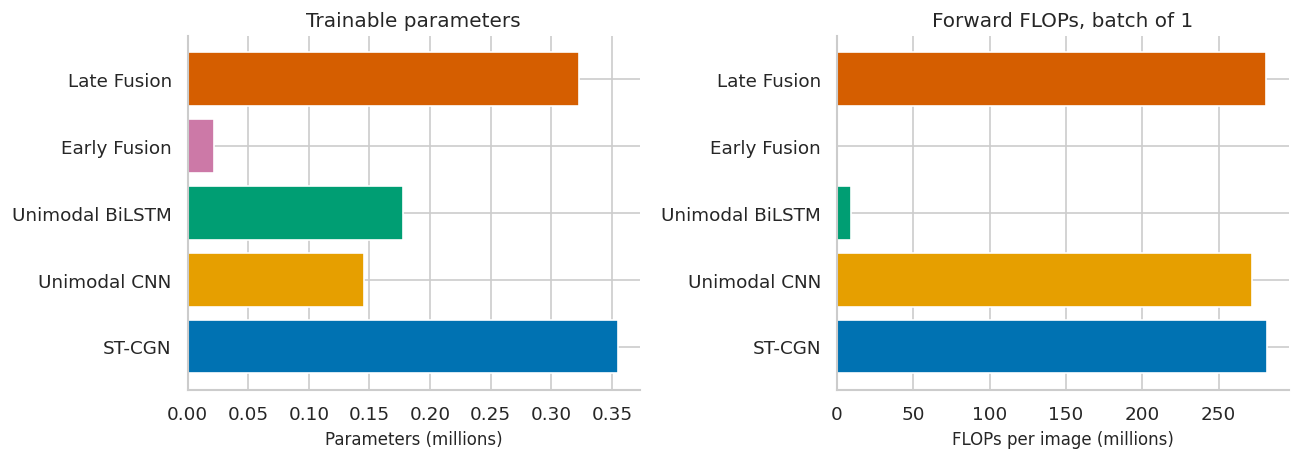

saved outputs/07_complexity.png
Native map side is 32. Attention is computed on 4x4 after adaptive pooling (480 scores per sample, not 30720).
Backbone receptive field: 23 pixels. Quadrant side: 64 pixels.


In [7]:
"""Parameter counts, hook-based FLOPs, and the asymptotic comparison table."""
class FlopMeter:
    """Forward-hook counter for convolutions, linear maps, and packed LSTMs."""

    def __init__(self) -> None:
        self.flops = 0
        self.handles: list = []

    def watch(self, model: nn.Module) -> None:
        for module in model.modules():
            if isinstance(module, nn.Conv2d):
                self.handles.append(module.register_forward_hook(self._conv))
            elif isinstance(module, nn.Linear):
                self.handles.append(module.register_forward_hook(self._linear))
            elif isinstance(module, nn.LSTM):
                self.handles.append(module.register_forward_hook(self._lstm))

    def close(self) -> None:
        for handle in self.handles:
            handle.remove()
        self.handles.clear()

    def _conv(self, module: nn.Conv2d, inputs, output: torch.Tensor) -> None:
        del inputs
        batch, out_channels, height, width = output.shape
        kernel_h, kernel_w = module.kernel_size
        macs = batch * out_channels * height * width * (module.in_channels // module.groups) * kernel_h * kernel_w
        self.flops += int(macs * 2)

    def _linear(self, module: nn.Linear, inputs, output: torch.Tensor) -> None:
        del inputs
        self.flops += int(output.numel() * module.in_features * 2)

    def _lstm(self, module: nn.LSTM, inputs, output) -> None:
        del output
        packed = inputs[0]
        if isinstance(packed, nn.utils.rnn.PackedSequence):
            tokens_processed = int(packed.batch_sizes.sum().item())
        else:
            tokens_processed = int(packed.shape[0] * packed.shape[1])
        directions = 2 if module.bidirectional else 1
        macs = 0
        for layer in range(module.num_layers):
            layer_in = module.input_size if layer == 0 else module.hidden_size * directions
            macs += tokens_processed * directions * 4 * module.hidden_size * (layer_in + module.hidden_size)
        self.flops += int(macs * 2)


def attention_matmul_flops(cfg: Config) -> int:
    """QK^T and the masked visual readout, which are not nn.Linear modules."""
    sites = cfg.attn_grid * cfg.attn_grid
    channels = cfg.cnn_channels[-1]
    return int(2 * sites * cfg.seq_len * cfg.attn_dim + 2 * sites * channels)


def profile_models(cfg: Config, device: torch.device) -> pd.DataFrame:
    images = torch.randn(1, cfg.in_channels, cfg.image_size, cfg.image_size, device=device)
    tokens = torch.randint(1, cfg.vocab_size, (1, cfg.seq_len), device=device)
    rows = []
    for name in MODEL_ORDER:
        model = build_model(name, cfg).to(device).eval()
        meter = FlopMeter()
        meter.watch(model)
        with torch.no_grad():
            model(images, tokens)
        flops = meter.flops + (attention_matmul_flops(cfg) if name == "ST-CGN" else 0)
        meter.close()
        params = count_parameters(model)
        thop_note = ""
        try:
            from thop import profile as thop_profile
            macs, thop_params = thop_profile(model, inputs=(images, tokens), verbose=False)
            thop_note = f"thop macs={int(macs):,}"
            del macs, thop_params
        except Exception as exc:
            thop_note = f"thop skipped ({type(exc).__name__})"
        rows.append(
            {
                "model": name,
                "parameters": params,
                "flops": flops,
                "param_MiB_fp32": params * 4 / (1024 ** 2),
                "adamw_state_MiB": params * 12 / (1024 ** 2),
                "cross_check": thop_note,
            }
        )
        del model
        release_memory()
    frame = pd.DataFrame(rows)
    asymptotics = {
        "ST-CGN": f"O(c^2 n^2 + t h^2 + R^2 t d), R={cfg.attn_grid}",
        "Unimodal CNN": "O(c^2 n^2)",
        "Unimodal BiLSTM": "O(t h (e + h))",
        "Early Fusion": "O(n^2 + t e + d^2)",
        "Late Fusion": "O(c^2 n^2 + t h^2)",
    }
    frame["time_complexity"] = frame["model"].map(asymptotics)
    frame["memory_complexity"] = frame["model"].map(
        {
            "ST-CGN": "O(c n^2 + t h + R^2 t)",
            "Unimodal CNN": "O(c n^2)",
            "Unimodal BiLSTM": "O(t h)",
            "Early Fusion": "O(d)",
            "Late Fusion": "O(c n^2 + t h)",
        }
    )
    return frame


COMPLEXITY = profile_models(CFG, DEVICE)
show = COMPLEXITY.copy()
show["parameters"] = show["parameters"].map(lambda value: f"{value:,}")
show["flops"] = show["flops"].map(lambda value: f"{value:,}")
show["param_MiB_fp32"] = show["param_MiB_fp32"].map(lambda value: f"{value:.2f}")
show["adamw_state_MiB"] = show["adamw_state_MiB"].map(lambda value: f"{value:.2f}")
display(show)
COMPLEXITY.to_csv(OUTPUT_DIR / "complexity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = list(MODEL_ORDER)
plot_df = COMPLEXITY.set_index("model").loc[order]
colors = [MODEL_COLORS[name] for name in order]
axes[0].barh(order, plot_df["parameters"] / 1e6, color=colors)
axes[0].set_xlabel("Parameters (millions)")
axes[0].set_title("Trainable parameters")
axes[1].barh(order, plot_df["flops"] / 1e6, color=colors)
axes[1].set_xlabel("FLOPs per image (millions)")
axes[1].set_title("Forward FLOPs, batch of 1")
fig.tight_layout()
save_show(fig, "07_complexity.png")
print(
    f"Native map side is {CFG.image_size // 4}. Attention is computed on "
    f"{CFG.attn_grid}x{CFG.attn_grid} after adaptive pooling "
    f"({CFG.attn_grid ** 2 * CFG.seq_len} scores per sample, not "
    f"{(CFG.image_size // 4) ** 2 * CFG.seq_len})."
)
print(f"Backbone receptive field: {receptive_field_pixels()} pixels. Quadrant side: {CFG.image_size // 2} pixels.")

## 4. Stratified 5-fold training

All five networks share the fold indices, the epoch count, AdamW, cosine annealing, gradient clipping at 1, dropout, and a class-weighted cross-entropy. Weights are inverse frequency on the **training** fold only, then rescaled to mean 1 so the loss magnitude stays comparable across folds. Image normalization also uses training-fold moments only.

Reported train metrics are computed in evaluation mode. The optimization loss still includes dropout, and plotting that number against a validation loss confuses regularization noise with overfitting. The curves below are therefore paired evaluation-mode passes. The checkpoint is the final epoch, not the best validation epoch, so the reported fold score is not chosen on the same split that is tested.

The experimental unit for later tests is the fold. A paired test on thousands of images would treat dependent tiles as independent replicates.

In [8]:
"""Shared optimization, evaluation, linear ceilings, and 5-fold training."""
def class_weights(labels: np.ndarray, num_classes: int) -> torch.Tensor:
    counts = np.bincount(labels, minlength=num_classes).astype(np.float64)
    weights = counts.sum() / (num_classes * np.maximum(counts, 1.0))
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32)


def decay_param_groups(model: nn.Module, weight_decay: float) -> list[dict]:
    decay, plain = [], []
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        if parameter.ndim == 1 or name.endswith(".bias"):
            plain.append(parameter)
        else:
            decay.append(parameter)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": plain, "weight_decay": 0.0},
    ]


def make_loader(dataset: MultimodalCropDataset, shuffle: bool, batch_size: int, seed: int, device: torch.device) -> torch.utils.data.DataLoader:
    generator = torch.Generator()
    generator.manual_seed(seed)
    drop_last = bool(shuffle and len(dataset) >= 2 * batch_size)
    return torch.utils.data.DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        generator=generator,
        pin_memory=device.type == "cuda",
        num_workers=0,
    )


def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray, num_classes: int, loss: float) -> dict[str, float]:
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", labels=list(range(num_classes)), zero_division=0
    )
    return {
        "loss": float(loss),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
    }


@torch.no_grad()
def evaluate(model: nn.Module, loader, criterion: nn.Module, device: torch.device, num_classes: int, return_aux: bool = False):
    model.eval()
    total_loss = 0.0
    total_n = 0
    truths, predictions, probabilities, indices = [], [], [], []
    attentions, gates = [], []
    with torch.inference_mode():
        for images, tokens, labels, index in loader:
            images = images.to(device, non_blocking=True)
            tokens = tokens.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            if return_aux:
                logits, aux = model(images, tokens, return_aux=True)
                attentions.append(aux["spatial_attention"].squeeze(1).detach().cpu().numpy())
                gates.append(aux["channel_gate"].detach().cpu().numpy())
            else:
                logits = model(images, tokens, return_aux=False)
            loss = criterion(logits, labels)
            total_loss += float(loss.item()) * int(labels.shape[0])
            total_n += int(labels.shape[0])
            probability = torch.softmax(logits, dim=-1)
            truths.append(labels.detach().cpu().numpy())
            predictions.append(probability.argmax(dim=1).detach().cpu().numpy())
            probabilities.append(probability.detach().cpu().numpy())
            indices.append(index.numpy())
    y_true = np.concatenate(truths)
    y_pred = np.concatenate(predictions)
    metrics = classification_metrics(y_true, y_pred, num_classes, total_loss / max(total_n, 1))
    extra = None
    if return_aux:
        extra = {"attn": np.concatenate(attentions).astype(np.float32), "gate": np.concatenate(gates).astype(np.float32)}
    return metrics, np.concatenate(probabilities), y_pred, np.concatenate(indices), extra


def fit_model(model, train_loader, train_eval_loader, val_loader, criterion, cfg: Config, device: torch.device, name: str, fold: int) -> dict:
    optimizer = torch.optim.AdamW(decay_param_groups(model, cfg.weight_decay), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
    keys = ("loss", "accuracy", "precision", "recall", "f1")
    history = {f"train_{key}": [] for key in keys}
    history.update({f"val_{key}": [] for key in keys})
    history["optim_loss"] = []
    for epoch in range(cfg.epochs):
        model.train()
        running = 0.0
        seen = 0
        for images, tokens, labels, _index in train_loader:
            images = images.to(device, non_blocking=True)
            tokens = tokens.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images, tokens, return_aux=False)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss in {name} fold {fold + 1} epoch {epoch + 1}.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            optimizer.step()
            running += float(loss.item()) * int(labels.shape[0])
            seen += int(labels.shape[0])
        scheduler.step()
        train_metrics = evaluate(model, train_eval_loader, criterion, device, cfg.num_classes)[0]
        val_metrics = evaluate(model, val_loader, criterion, device, cfg.num_classes)[0]
        history["optim_loss"].append(running / max(seen, 1))
        for key in keys:
            history[f"train_{key}"].append(train_metrics[key])
            history[f"val_{key}"].append(val_metrics[key])
        print(
            f"  [{name}] fold {fold + 1} epoch {epoch + 1:02d}/{cfg.epochs} "
            f"train_loss {train_metrics['loss']:.3f} val_loss {val_metrics['loss']:.3f} "
            f"val_acc {val_metrics['accuracy']:.3f} val_P {val_metrics['precision']:.3f} "
            f"val_R {val_metrics['recall']:.3f} val_F1 {val_metrics['f1']:.3f}"
        )
    return history


def run_neural_cv(bundle: DataBundle, splits, cfg: Config, device: torch.device):
    n_rows = len(bundle.labels)
    oof_pred = {name: np.full(n_rows, -1, dtype=np.int64) for name in MODEL_ORDER}
    oof_proba = {name: np.zeros((n_rows, cfg.num_classes), dtype=np.float64) for name in MODEL_ORDER}
    history = {name: {} for name in MODEL_ORDER}
    attention = np.full((n_rows, cfg.attn_grid, cfg.attn_grid), np.nan, dtype=np.float32)
    gates = np.full((n_rows, cfg.cnn_channels[-1]), np.nan, dtype=np.float32)
    rows = []
    for fold, (train_index, val_index) in enumerate(splits):
        print(f"\n========== Fold {fold + 1}/{cfg.n_folds} | train {len(train_index)} | val {len(val_index)} ==========")
        mean = bundle.images[train_index].mean(axis=(0, 2, 3), keepdims=True)
        std = np.maximum(bundle.images[train_index].std(axis=(0, 2, 3), keepdims=True), 1e-6)
        normalized = ((bundle.images - mean) / std).astype(np.float32)
        train_ds = MultimodalCropDataset(normalized[train_index], bundle.tokens[train_index], bundle.labels[train_index], train_index, cfg.pad_idx)
        val_ds = MultimodalCropDataset(normalized[val_index], bundle.tokens[val_index], bundle.labels[val_index], val_index, cfg.pad_idx)
        weights = class_weights(bundle.labels[train_index], cfg.num_classes).to(device)
        criterion = nn.CrossEntropyLoss(weight=weights)
        print("class weights:", {CLASS_NAMES[i]: round(float(weights[i]), 3) for i in range(cfg.num_classes)})
        for name in MODEL_ORDER:
            set_seed(cfg.SEED + fold)
            model = build_model(name, cfg).to(device)
            train_loader = make_loader(train_ds, True, cfg.batch_size, cfg.SEED + fold, device)
            train_eval_loader = make_loader(train_ds, False, cfg.batch_size, cfg.SEED + fold, device)
            val_loader = make_loader(val_ds, False, cfg.batch_size, cfg.SEED + fold, device)
            try:
                history[name][fold] = fit_model(model, train_loader, train_eval_loader, val_loader, criterion, cfg, device, name, fold)
                metrics, probability, prediction, indices, extra = evaluate(
                    model, val_loader, criterion, device, cfg.num_classes, return_aux=(name == "ST-CGN")
                )
            except RuntimeError as exc:
                release_memory()
                if "out of memory" in str(exc).lower():
                    raise RuntimeError(
                        f"CUDA out of memory while training {name}, fold {fold + 1}. "
                        "Lower Config.batch_size or Config.image_size, or set DEBUG_MODE=True."
                    ) from exc
                raise
            oof_pred[name][indices] = prediction
            oof_proba[name][indices] = probability
            if extra is not None:
                attention[indices] = extra["attn"]
                gates[indices] = extra["gate"]
            rows.append({"model": name, "fold": fold + 1, **metrics})
            print(
                f"  FINAL {name} fold {fold + 1}: "
                f"acc {metrics['accuracy']:.3f} P {metrics['precision']:.3f} "
                f"R {metrics['recall']:.3f} F1 {metrics['f1']:.3f}"
            )
            del model
            release_memory()
            pd.DataFrame(rows).to_csv(OUTPUT_DIR / "fold_metrics_partial.csv", index=False)
    for name in MODEL_ORDER:
        if int(oof_pred[name].min()) < 0:
            raise RuntimeError(f"Out-of-fold predictions for {name} do not cover every sample.")
    return history, oof_pred, oof_proba, attention, gates, pd.DataFrame(rows)


def token_histogram(tokens: np.ndarray, vocab_size: int) -> np.ndarray:
    histogram = np.zeros((len(tokens), vocab_size), dtype=np.float32)
    for index, row in enumerate(tokens):
        values, counts = np.unique(row, return_counts=True)
        histogram[index, values] = counts
    return histogram / tokens.shape[1]


def image_moments(images: np.ndarray) -> np.ndarray:
    return np.concatenate([images.mean(axis=(2, 3)), images.std(axis=(2, 3))], axis=1).astype(np.float32)


def trusted_moments(images: np.ndarray, quadrants: np.ndarray) -> np.ndarray:
    features = []
    side = images.shape[-1]
    for image, quadrant in zip(images, quadrants):
        rows, cols = quadrant_slices(int(quadrant), side)
        patch = image[:, rows, cols]
        features.append(np.concatenate([patch.mean(axis=(1, 2)), patch.std(axis=(1, 2))]))
    return np.asarray(features, dtype=np.float32)


def probe_macro_f1(features: np.ndarray, labels: np.ndarray, splits, majority: bool = False) -> np.ndarray:
    scores = []
    for train_index, val_index in splits:
        if majority:
            choice = int(np.bincount(labels[train_index]).argmax())
            prediction = np.full(len(val_index), choice, dtype=np.int64)
        else:
            scaler = StandardScaler()
            train_x = scaler.fit_transform(features[train_index])
            val_x = scaler.transform(features[val_index])
            classifier = LogisticRegression(max_iter=600, class_weight="balanced")
            classifier.fit(train_x, labels[train_index])
            prediction = classifier.predict(val_x)
        scores.append(f1_score(labels[val_index], prediction, average="macro", zero_division=0, labels=list(range(len(CLASS_NAMES)))))
    return np.asarray(scores, dtype=np.float64)


SPLITS = list(
    StratifiedKFold(n_splits=CFG.n_folds, shuffle=True, random_state=CFG.SEED).split(np.zeros(len(BUNDLE.labels)), BUNDLE.labels)
)
print(f"prepared {len(SPLITS)} stratified folds")

PROBE_FEATURES = {
    "Majority class": None,
    "Orderless token histogram": token_histogram(BUNDLE.tokens, CFG.vocab_size),
    "Global spectral moments": image_moments(BUNDLE.images),
    "Early-fusion features (linear)": np.concatenate(
        [image_moments(BUNDLE.images), token_histogram(BUNDLE.tokens, CFG.vocab_size)], axis=1
    ),
}
if BUNDLE.quadrants is not None:
    PROBE_FEATURES["Oracle: trusted quadrant + climate metadata"] = np.concatenate(
        [trusted_moments(BUNDLE.images, BUNDLE.quadrants), BUNDLE.climate], axis=1
    )

PROBE_SCORES = {}
for probe_name, features in PROBE_FEATURES.items():
    PROBE_SCORES[probe_name] = probe_macro_f1(
        np.zeros((len(BUNDLE.labels), 1)) if features is None else features,
        BUNDLE.labels,
        SPLITS,
        majority=features is None,
    )
probe_table = pd.DataFrame(
    {
        "probe": list(PROBE_SCORES),
        "macro_f1_mean": [float(np.mean(scores)) for scores in PROBE_SCORES.values()],
        "macro_f1_std": [float(np.std(scores, ddof=1)) for scores in PROBE_SCORES.values()],
    }
)
print("Linear ceilings on the same folds. The oracle uses the hidden quadrant index and is not a baseline.")
display(probe_table.round(3))
probe_table.to_csv(OUTPUT_DIR / "linear_probes.csv", index=False)

print("\nStarting neural cross-validation. This is the long cell.")
HISTORY, OOF_PRED, OOF_PROBA, OOF_ATTENTION, OOF_GATES, FOLD_METRICS = run_neural_cv(BUNDLE, SPLITS, CFG, DEVICE)
FOLD_METRICS.to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
display(FOLD_METRICS.round(3))

prepared 5 stratified folds
Linear ceilings on the same folds. The oracle uses the hidden quadrant index and is not a baseline.


,probe,macro_f1_mean,macro_f1_std
0,Majority class,0.118,0.000
1,Orderless token histogram,0.398,0.009
2,Global spectral moments,0.290,0.030
3,Early-fusion features (linear),0.562,0.036
4,Oracle: trusted quadrant + climate metadata,1.000,0.000



Starting neural cross-validation. This is the long cell.

========== Fold 1/5 | train 1600 | val 400 ==========
class weights: {'Healthy': 0.359, 'Nitrogen Deficiency': 0.682, 'Drought Stress': 0.968, 'Weed Infestation': 1.238, 'Waterway Encroachment': 1.753}
  [ST-CGN] fold 1 epoch 01/15 train_loss 0.930 val_loss 1.019 val_acc 0.445 val_P 0.487 val_R 0.530 val_F1 0.419
  [ST-CGN] fold 1 epoch 02/15 train_loss 0.754 val_loss 0.783 val_acc 0.583 val_P 0.629 val_R 0.675 val_F1 0.593
  [ST-CGN] fold 1 epoch 03/15 train_loss 0.135 val_loss 0.145 val_acc 0.965 val_P 0.954 val_R 0.979 val_F1 0.965
  [ST-CGN] fold 1 epoch 04/15 train_loss 0.006 val_loss 0.003 val_acc 1.000 val_P 1.000 val_R 1.000 val_F1 1.000
  [ST-CGN] fold 1 epoch 05/15 train_loss 0.001 val_loss 0.001 val_acc 1.000 val_P 1.000 val_R 1.000 val_F1 1.000
  [ST-CGN] fold 1 epoch 06/15 train_loss 0.000 val_loss 0.000 val_acc 1.000 val_P 1.000 val_R 1.000 val_F1 1.000
  [ST-CGN] fold 1 epoch 07/15 train_loss 0.000 val_loss 0.000

,model,fold,loss,accuracy,precision,recall,f1
0,ST-CGN,1,0.000,1.000,1.000,1.000,1.000
1,Unimodal CNN,1,1.116,0.345,0.281,0.457,0.329
2,Unimodal BiLSTM,1,1.026,0.448,0.357,0.522,0.388
3,Early Fusion,1,0.675,0.555,0.555,0.651,0.551
4,Late Fusion,1,0.700,0.538,0.547,0.669,0.550
5,ST-CGN,2,0.005,1.000,1.000,1.000,1.000
6,Unimodal CNN,2,1.102,0.350,0.370,0.459,0.328
7,Unimodal BiLSTM,2,0.985,0.478,0.444,0.553,0.424
8,Early Fusion,2,0.603,0.560,0.555,0.698,0.580
9,Late Fusion,2,0.638,0.542,0.542,0.667,0.565


## 5. Comparative results

Tables report the mean and sample standard deviation across the five final-epoch validation scores. Out-of-fold predictions cover every sample exactly once and are the source of the confusion matrices, ROC curves, and precision-recall curves. Attention maps are the ST-CGN masks on those same out-of-fold forwards.

The linear probes from the previous section are the reference for whether a gain is real. An orderless model that merely matches the early-fusion probe has not used marker position. A model that approaches the oracle has recovered the nominated quadrant. The oracle is not entered in the significance tests, because it is given a coordinate the other models do not receive.

Validation metrics at the final epoch, mean ± sample standard deviation over folds


,model,accuracy,precision,recall,macro_f1
0,ST-CGN,0.929 ± 0.159,0.926 ± 0.166,0.945 ± 0.123,0.931 ± 0.154
1,Late Fusion,0.552 ± 0.015,0.550 ± 0.013,0.673 ± 0.017,0.568 ± 0.019
2,Early Fusion,0.557 ± 0.020,0.549 ± 0.022,0.669 ± 0.029,0.564 ± 0.028
3,Unimodal BiLSTM,0.447 ± 0.021,0.374 ± 0.043,0.523 ± 0.024,0.392 ± 0.023
4,Unimodal CNN,0.338 ± 0.021,0.282 ± 0.055,0.439 ± 0.023,0.312 ± 0.026


Out-of-fold per-class F1


model,ST-CGN,Unimodal CNN,Unimodal BiLSTM,Early Fusion,Late Fusion
class,,,,,
Healthy,0.930,0.002,0.501,0.463,0.407
Nitrogen Deficiency,0.926,0.498,0.013,0.466,0.512
Drought Stress,0.941,0.350,0.678,0.762,0.757
Weed Infestation,0.946,0.442,0.370,0.660,0.655
Waterway Encroachment,0.888,0.271,0.406,0.471,0.507


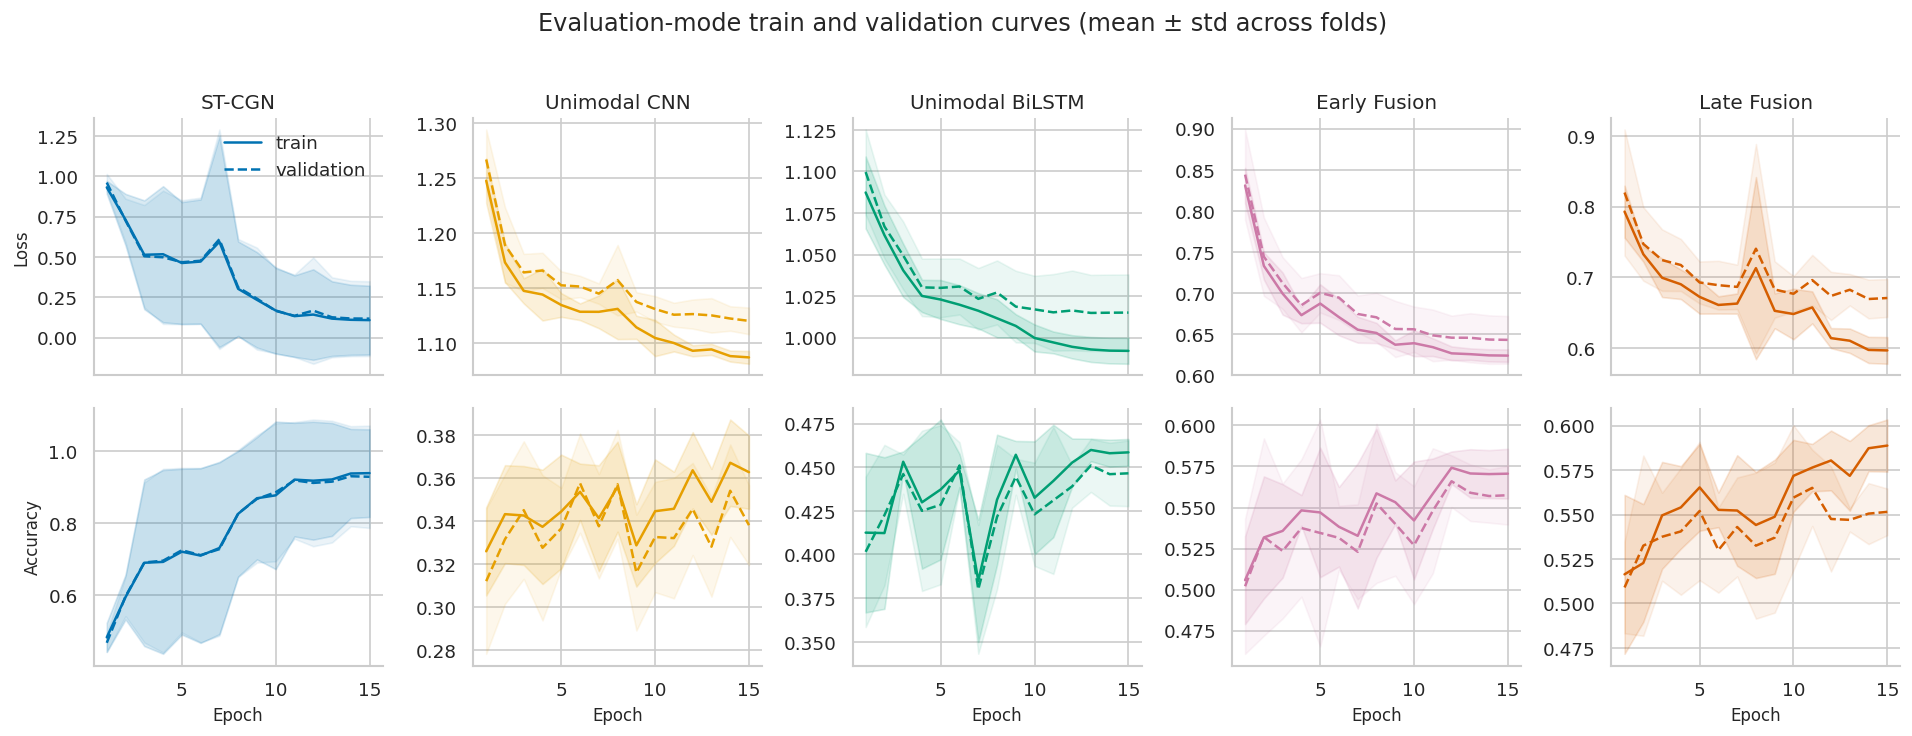

saved outputs/08_convergence.png


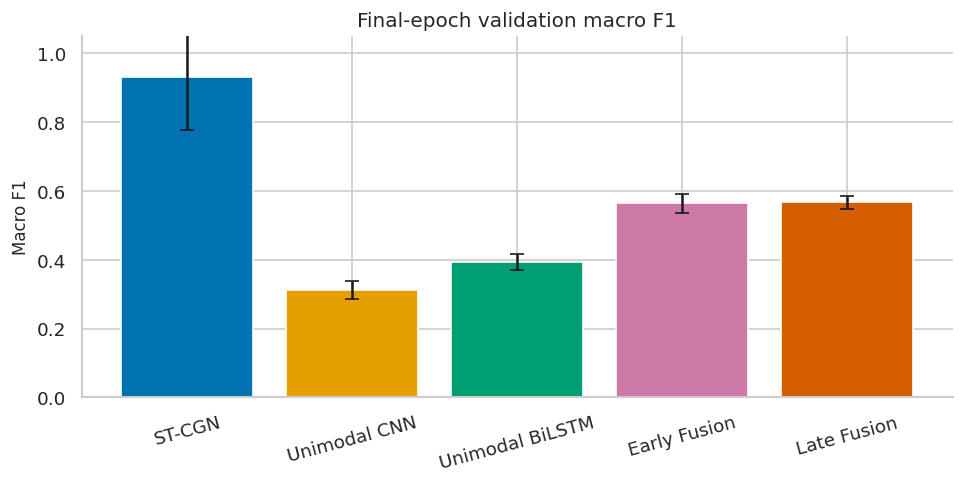

saved outputs/09_macro_f1.png


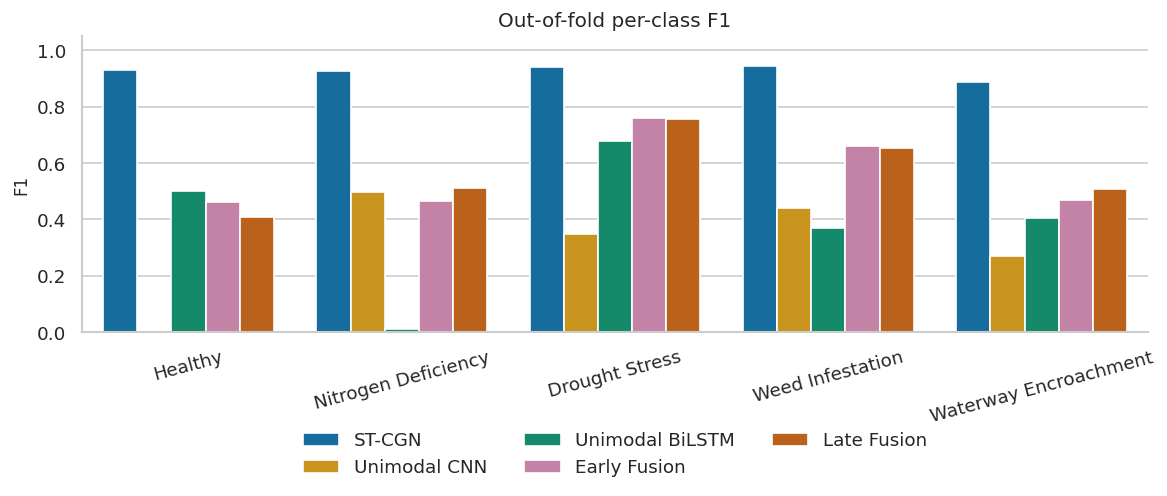

saved outputs/10_per_class_f1.png


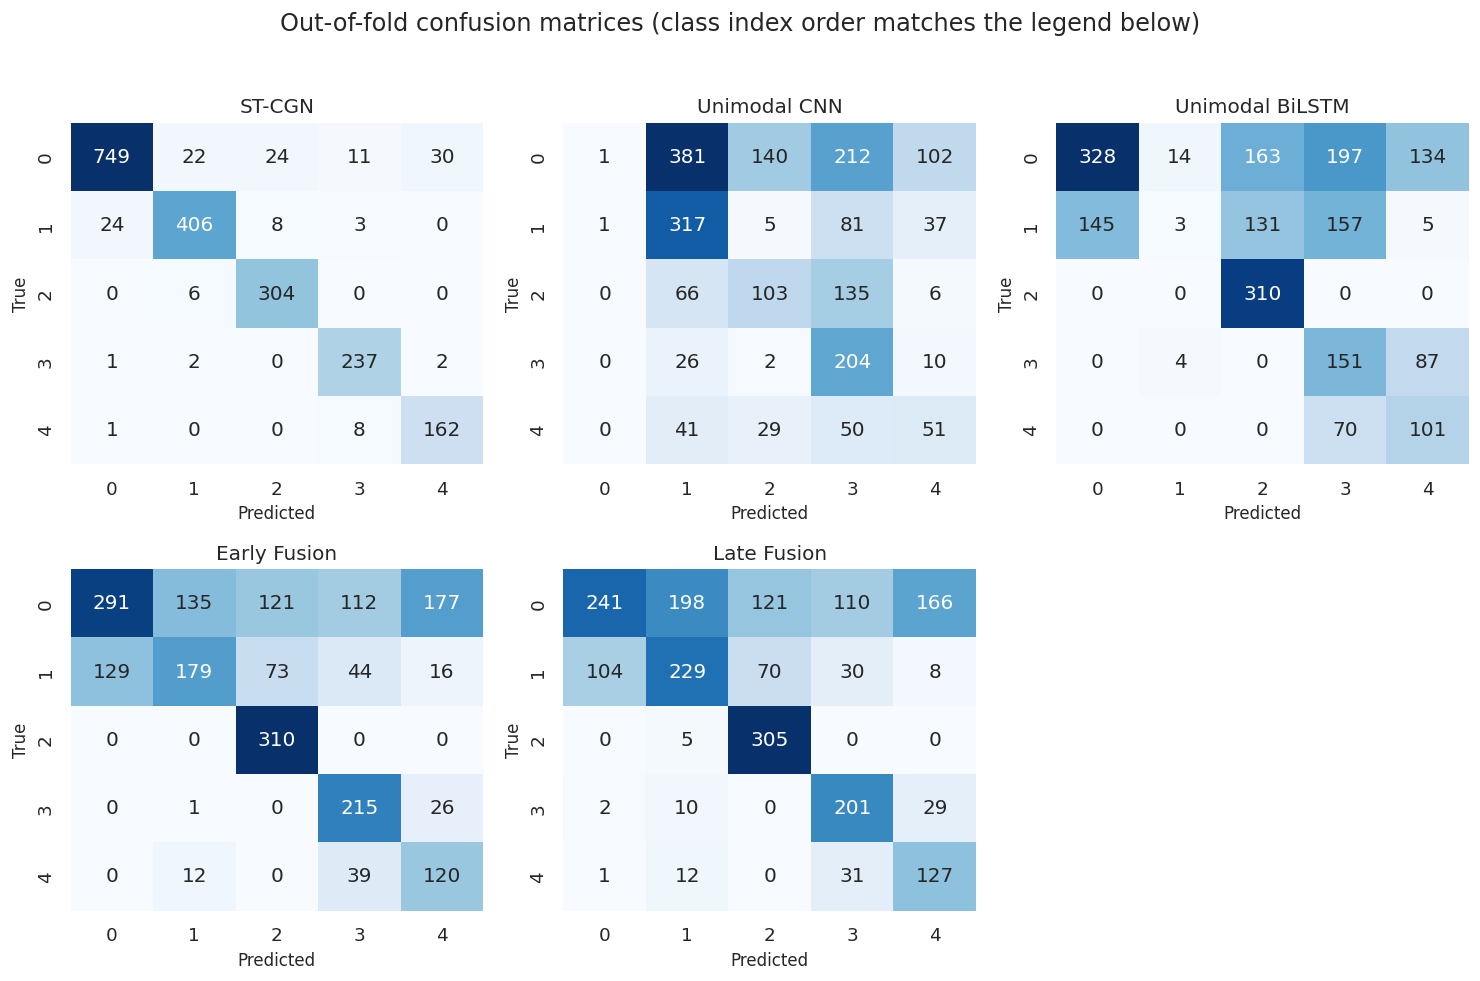

saved outputs/11_confusion.png
class index: {0: 'Healthy', 1: 'Nitrogen Deficiency', 2: 'Drought Stress', 3: 'Weed Infestation', 4: 'Waterway Encroachment'}


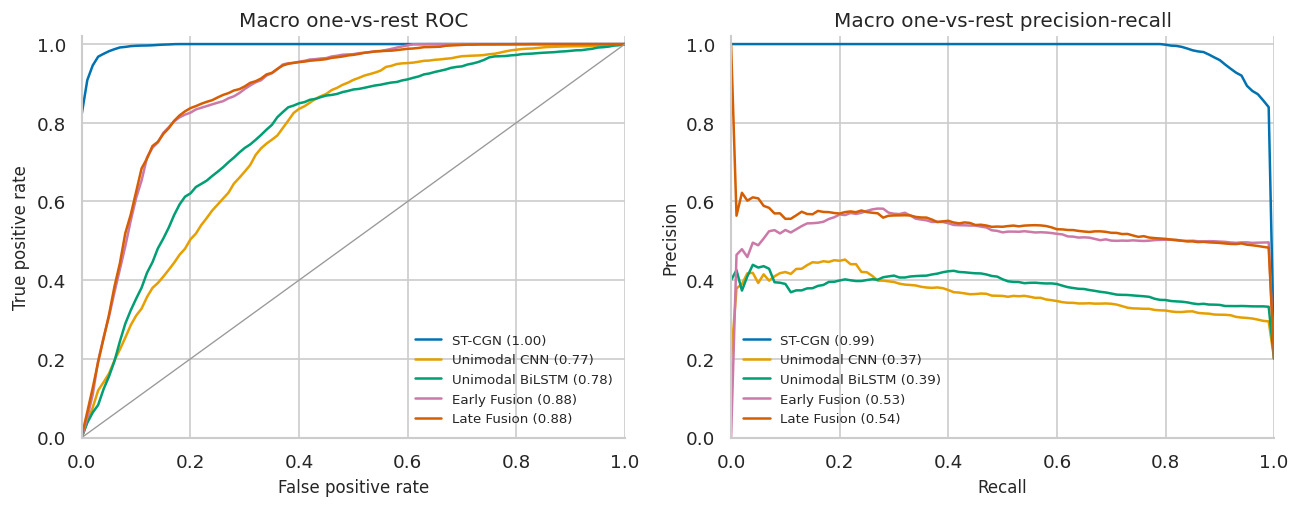

saved outputs/12_roc_pr.png


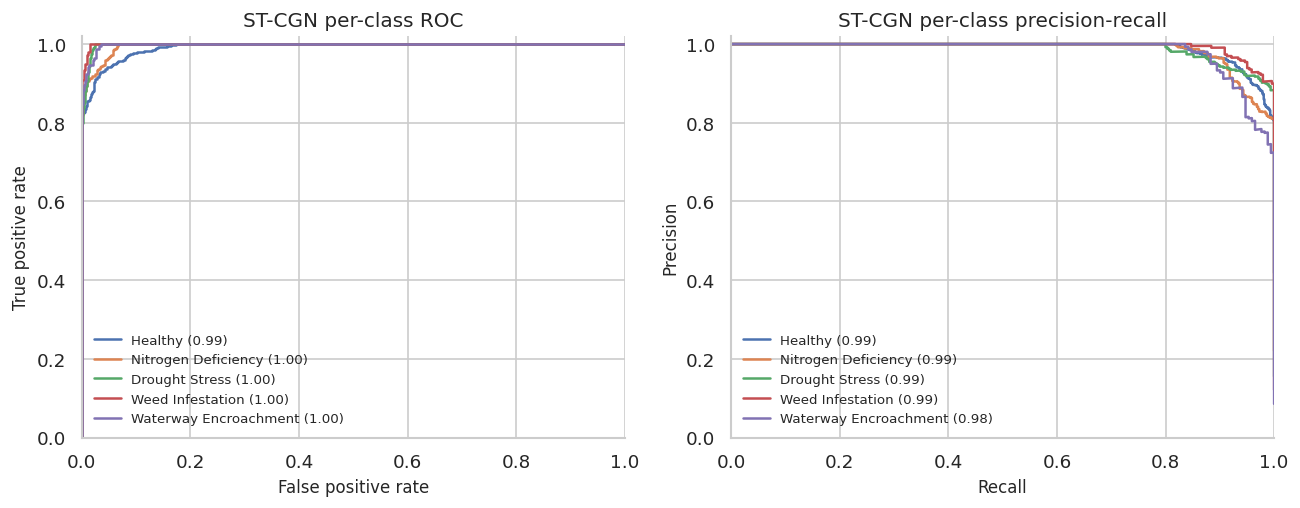

saved outputs/13_stcgn_roc_pr.png
Mean attention mass inside the trusted quadrant: 0.613 (chance = 0.25, std 0.318).


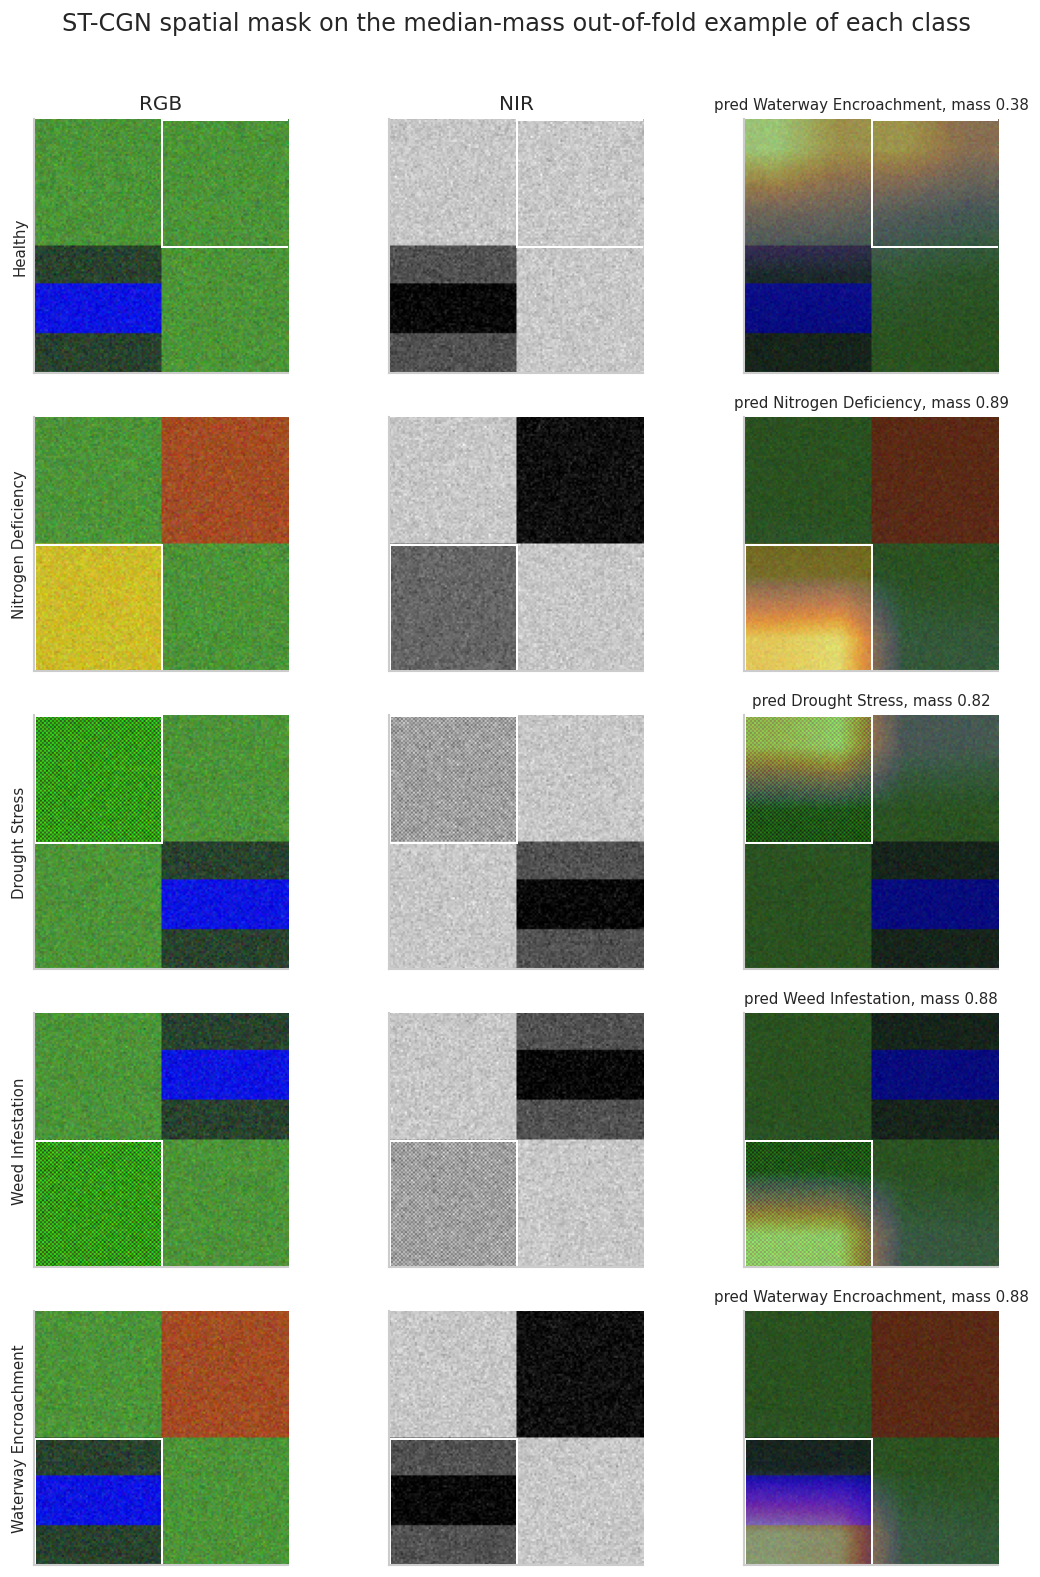

saved outputs/14_attention_overlay.png


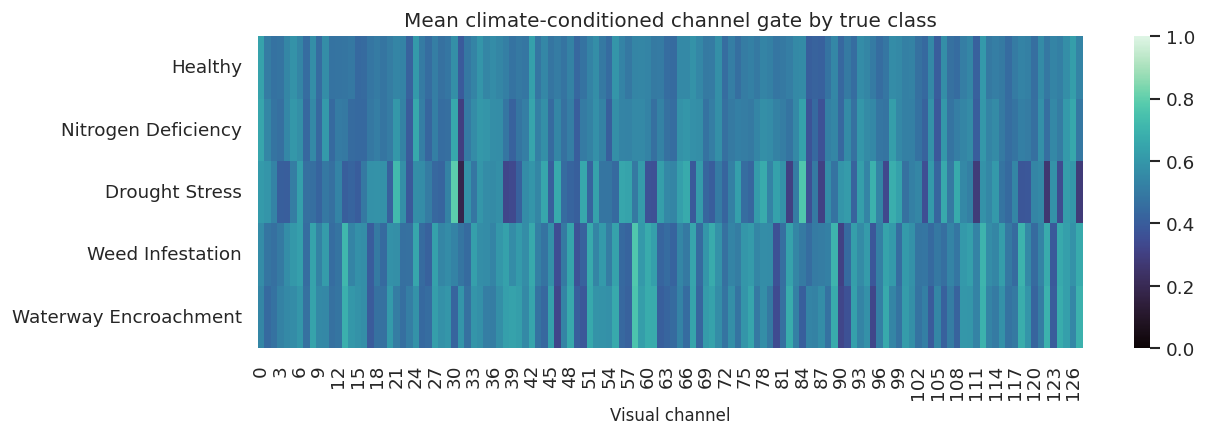

saved outputs/15_channel_gates.png
L1 distance between drought and waterway mean gates: 19.396
saved outputs/oof_predictions.npz


In [9]:
"""Summary tables, convergence curves, confusion matrices, ROC/PR, attention and gates."""
def mean_std(values: np.ndarray) -> str:
    return f"{np.mean(values):.3f} ± {np.std(values, ddof=1):.3f}"


def fold_vector(history: dict, model: str, key: str, n_folds: int) -> np.ndarray:
    return np.asarray([history[model][fold][key][-1] for fold in range(n_folds)], dtype=np.float64)


SUMMARY_ROWS = []
for model_name in MODEL_ORDER:
    SUMMARY_ROWS.append(
        {
            "model": model_name,
            "accuracy": mean_std(fold_vector(HISTORY, model_name, "val_accuracy", CFG.n_folds)),
            "precision": mean_std(fold_vector(HISTORY, model_name, "val_precision", CFG.n_folds)),
            "recall": mean_std(fold_vector(HISTORY, model_name, "val_recall", CFG.n_folds)),
            "macro_f1": mean_std(fold_vector(HISTORY, model_name, "val_f1", CFG.n_folds)),
            "macro_f1_mean": float(np.mean(fold_vector(HISTORY, model_name, "val_f1", CFG.n_folds))),
        }
    )
SUMMARY = pd.DataFrame(SUMMARY_ROWS).sort_values("macro_f1_mean", ascending=False)
print("Validation metrics at the final epoch, mean ± sample standard deviation over folds")
display(SUMMARY.drop(columns=["macro_f1_mean"]).reset_index(drop=True))
SUMMARY.to_csv(OUTPUT_DIR / "summary_metrics.csv", index=False)

per_class_rows = []
for model_name in MODEL_ORDER:
    scores = f1_score(BUNDLE.labels, OOF_PRED[model_name], average=None, labels=list(range(CFG.num_classes)), zero_division=0)
    for class_id, score in enumerate(scores):
        per_class_rows.append({"model": model_name, "class": CLASS_NAMES[class_id], "f1": float(score)})
PER_CLASS = pd.DataFrame(per_class_rows)
print("Out-of-fold per-class F1")
display(PER_CLASS.pivot(index="class", columns="model", values="f1").reindex(CLASS_NAMES)[list(MODEL_ORDER)].round(3))
PER_CLASS.to_csv(OUTPUT_DIR / "per_class_f1.csv", index=False)


def plot_convergence(history: dict, cfg: Config) -> None:
    fig, axes = plt.subplots(2, len(MODEL_ORDER), figsize=(16, 6), sharex=True)
    epochs = np.arange(1, cfg.epochs + 1)
    for column, model_name in enumerate(MODEL_ORDER):
        for row, (train_key, val_key, ylabel) in enumerate(
            (("train_loss", "val_loss", "Loss"), ("train_accuracy", "val_accuracy", "Accuracy"))
        ):
            train = np.vstack([history[model_name][fold][train_key] for fold in range(cfg.n_folds)])
            val = np.vstack([history[model_name][fold][val_key] for fold in range(cfg.n_folds)])
            axis = axes[row, column]
            axis.plot(epochs, train.mean(0), color=MODEL_COLORS[model_name], label="train")
            axis.fill_between(epochs, train.mean(0) - train.std(0), train.mean(0) + train.std(0), color=MODEL_COLORS[model_name], alpha=0.15)
            axis.plot(epochs, val.mean(0), color=MODEL_COLORS[model_name], linestyle="--", label="validation")
            axis.fill_between(epochs, val.mean(0) - val.std(0), val.mean(0) + val.std(0), color=MODEL_COLORS[model_name], alpha=0.08)
            if row == 0:
                axis.set_title(model_name)
            if column == 0:
                axis.set_ylabel(ylabel)
            if row == 1:
                axis.set_xlabel("Epoch")
            if column == 0 and row == 0:
                axis.legend(loc="best")
    fig.suptitle("Evaluation-mode train and validation curves (mean ± std across folds)", y=1.02)
    fig.tight_layout()
    save_show(fig, "08_convergence.png")


def plot_f1_bars(history: dict, cfg: Config) -> None:
    means, stds = [], []
    for model_name in MODEL_ORDER:
        scores = fold_vector(history, model_name, "val_f1", cfg.n_folds)
        means.append(float(scores.mean()))
        stds.append(float(scores.std(ddof=1)))
    fig, ax = plt.subplots(figsize=(8.2, 4.2))
    ax.bar(list(MODEL_ORDER), means, yerr=stds, color=[MODEL_COLORS[name] for name in MODEL_ORDER], capsize=4)
    ax.set_ylabel("Macro F1")
    ax.set_ylim(0, 1.05)
    ax.set_title("Final-epoch validation macro F1")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()
    save_show(fig, "09_macro_f1.png")


def plot_per_class(frame: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(10, 4.6))
    sns.barplot(data=frame, x="class", y="f1", hue="model", palette=MODEL_COLORS, ax=ax)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("")
    ax.set_ylabel("F1")
    ax.set_title("Out-of-fold per-class F1")
    ax.tick_params(axis="x", rotation=15)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
    fig.tight_layout()
    save_show(fig, "10_per_class_f1.png")


def plot_confusion(labels: np.ndarray, predictions: dict[str, np.ndarray]) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(12.5, 8))
    for axis, model_name in zip(axes.ravel(), MODEL_ORDER):
        matrix = confusion_matrix(labels, predictions[model_name], labels=list(range(len(CLASS_NAMES))))
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis, xticklabels=range(len(CLASS_NAMES)), yticklabels=range(len(CLASS_NAMES)))
        axis.set_title(model_name)
        axis.set_xlabel("Predicted")
        axis.set_ylabel("True")
    axes.ravel()[-1].axis("off")
    fig.suptitle("Out-of-fold confusion matrices (class index order matches the legend below)", y=1.02)
    fig.tight_layout()
    save_show(fig, "11_confusion.png")
    print("class index:", {index: name for index, name in enumerate(CLASS_NAMES)})


def _macro_curves(labels: np.ndarray, probability: np.ndarray, curve: str) -> tuple[np.ndarray, np.ndarray, float]:
    binary = label_binarize(labels, classes=list(range(probability.shape[1])))
    grid = np.linspace(0.0, 1.0, 101)
    collected = []
    scalar = []
    for class_id in range(probability.shape[1]):
        if binary[:, class_id].sum() == 0:
            continue
        if curve == "roc":
            x_value, y_value, _ = roc_curve(binary[:, class_id], probability[:, class_id])
            scalar.append(auc(x_value, y_value))
            collected.append(np.interp(grid, x_value, y_value))
        else:
            precision, recall, _ = precision_recall_curve(binary[:, class_id], probability[:, class_id])
            scalar.append(average_precision_score(binary[:, class_id], probability[:, class_id]))
            collected.append(np.interp(grid, recall[::-1], precision[::-1]))
    return grid, np.mean(collected, axis=0), float(np.mean(scalar))


def plot_roc_pr(labels: np.ndarray, probabilities: dict[str, np.ndarray]) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for model_name in MODEL_ORDER:
        x_roc, y_roc, roc_auc = _macro_curves(labels, probabilities[model_name], "roc")
        x_pr, y_pr, ap = _macro_curves(labels, probabilities[model_name], "pr")
        axes[0].plot(x_roc, y_roc, color=MODEL_COLORS[model_name], label=f"{model_name} ({roc_auc:.2f})")
        axes[1].plot(x_pr, y_pr, color=MODEL_COLORS[model_name], label=f"{model_name} ({ap:.2f})")
    axes[0].plot([0, 1], [0, 1], color="0.6", linewidth=0.8)
    axes[0].set_title("Macro one-vs-rest ROC")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[1].set_title("Macro one-vs-rest precision-recall")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    for axis in axes:
        axis.set_xlim(0, 1)
        axis.set_ylim(0, 1.02)
        axis.legend(fontsize=8, loc="best")
    fig.tight_layout()
    save_show(fig, "12_roc_pr.png")

    binary = label_binarize(labels, classes=list(range(CFG.num_classes)))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    for class_id, name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(binary[:, class_id], probabilities["ST-CGN"][:, class_id])
        precision, recall, _ = precision_recall_curve(binary[:, class_id], probabilities["ST-CGN"][:, class_id])
        axes[0].plot(fpr, tpr, label=f"{name} ({auc(fpr, tpr):.2f})")
        axes[1].plot(recall, precision, label=f"{name} ({average_precision_score(binary[:, class_id], probabilities['ST-CGN'][:, class_id]):.2f})")
    axes[0].set_title("ST-CGN per-class ROC")
    axes[1].set_title("ST-CGN per-class precision-recall")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    for axis in axes:
        axis.legend(fontsize=8)
        axis.set_xlim(0, 1)
        axis.set_ylim(0, 1.02)
    fig.tight_layout()
    save_show(fig, "13_stcgn_roc_pr.png")


def attention_masses(attention: np.ndarray, quadrants: np.ndarray) -> np.ndarray:
    masses = np.empty(len(quadrants), dtype=np.float32)
    for index, quadrant in enumerate(quadrants):
        rows, cols = quadrant_slices(int(quadrant), attention.shape[-1])
        masses[index] = float(attention[index, rows, cols].sum())
    return masses


def plot_attention(bundle: DataBundle, attention: np.ndarray, predictions: np.ndarray) -> None:
    side = bundle.images.shape[-1]
    masses = attention_masses(attention, bundle.quadrants) if bundle.quadrants is not None else None
    if masses is not None:
        print(
            f"Mean attention mass inside the trusted quadrant: {masses.mean():.3f} "
            f"(chance = 0.25, std {masses.std(ddof=1):.3f})."
        )
    fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(9.5, 13))
    for row, class_id in enumerate(range(len(CLASS_NAMES))):
        candidates = np.where(bundle.labels == class_id)[0]
        if masses is None:
            chosen = int(candidates[0])
        else:
            class_mass = masses[candidates]
            chosen = int(candidates[np.argmin(np.abs(class_mass - np.median(class_mass)))])
        image = bundle.images[chosen]
        rgb = np.clip(np.transpose(image[:3], (1, 2, 0)), 0, 1)
        heat = torch.nn.functional.interpolate(
            torch.tensor(attention[chosen])[None, None],
            size=(side, side),
            mode="bilinear",
            align_corners=False,
        )[0, 0].numpy()
        heat = (heat - heat.min()) / (heat.max() - heat.min() + 1e-8)
        color = plt.cm.magma(heat)[..., :3]
        overlay = np.clip(0.55 * rgb + 0.45 * color, 0, 1)
        axes[row, 0].imshow(rgb)
        axes[row, 0].set_ylabel(CLASS_NAMES[class_id], fontsize=9)
        axes[row, 1].imshow(image[3], cmap="gray", vmin=0, vmax=1)
        axes[row, 2].imshow(overlay)
        if bundle.quadrants is not None:
            q_rows, q_cols = quadrant_slices(int(bundle.quadrants[chosen]), side)
            for axis in axes[row]:
                axis.add_patch(
                    plt.Rectangle(
                        (q_cols.start, q_rows.start),
                        q_cols.stop - q_cols.start,
                        q_rows.stop - q_rows.start,
                        fill=False,
                        edgecolor="white",
                        linewidth=1.2,
                    )
                )
        pred_name = CLASS_NAMES[int(predictions[chosen])]
        mass_text = f", mass {masses[chosen]:.2f}" if masses is not None else ""
        axes[row, 2].set_title(f"pred {pred_name}{mass_text}", fontsize=9)
        for axis in axes[row]:
            axis.set_xticks([])
            axis.set_yticks([])
    axes[0, 0].set_title("RGB")
    axes[0, 1].set_title("NIR")
    fig.suptitle("ST-CGN spatial mask on the median-mass out-of-fold example of each class", y=1.01)
    fig.tight_layout()
    save_show(fig, "14_attention_overlay.png")


def plot_gates(gates: np.ndarray, labels: np.ndarray) -> None:
    means = np.vstack([gates[labels == class_id].mean(axis=0) for class_id in range(len(CLASS_NAMES))])
    fig, ax = plt.subplots(figsize=(11, 3.8))
    sns.heatmap(means, cmap="mako", vmin=0, vmax=1, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel("Visual channel")
    ax.set_title("Mean climate-conditioned channel gate by true class")
    fig.tight_layout()
    save_show(fig, "15_channel_gates.png")
    drought = means[CLASS_NAMES.index("Drought Stress")]
    water = means[CLASS_NAMES.index("Waterway Encroachment")]
    print(f"L1 distance between drought and waterway mean gates: {np.abs(drought - water).sum():.3f}")


plot_convergence(HISTORY, CFG)
plot_f1_bars(HISTORY, CFG)
plot_per_class(PER_CLASS)
plot_confusion(BUNDLE.labels, OOF_PRED)
plot_roc_pr(BUNDLE.labels, OOF_PROBA)
if np.isnan(OOF_ATTENTION).any():
    raise RuntimeError("ST-CGN attention maps were not stored for every sample.")
plot_attention(BUNDLE, OOF_ATTENTION, OOF_PRED["ST-CGN"])
plot_gates(OOF_GATES, BUNDLE.labels)

np.savez_compressed(
    OUTPUT_DIR / "oof_predictions.npz",
    y_true=BUNDLE.labels,
    **{f"pred_{name.lower().replace(' ', '_').replace('-', '_')}": OOF_PRED[name] for name in MODEL_ORDER},
    **{f"proba_{name.lower().replace(' ', '_').replace('-', '_')}": OOF_PROBA[name] for name in MODEL_ORDER},
)
print(f"saved {OUTPUT_DIR / 'oof_predictions.npz'}")

## 6. Statistical significance

The pre-registered comparisons are four paired contrasts of final-epoch macro F1: ST-CGN against each neural baseline. The pairing key is the fold, so \(n = 5\). A test on individual images would inflate the degrees of freedom by treating tiles that share a fold as independent.

The confirmatory test is the paired two-tailed \(t\)-test. The family-wise threshold is Bonferroni, \(\alpha = 0.05 / 4 = 0.0125\). Holm adjustment is reported beside it. The effect size is the paired Cohen's \(d_z = \bar d / s_d\).

The Wilcoxon signed-rank test is the distribution-free companion, also two-tailed, with zero differences discarded. With five nonzero pairs of the same sign, the two-sided exact \(p\)-value cannot be smaller than \(2 / 2^5 = 0.0625\). A result of 0.0625 is the most extreme outcome this test can return at this sample size. It does not, by itself, reject at 0.05. That is a property of the discrete null distribution, not evidence that the fold differences are small. The \(t\)-test remains the test that can resolve \(\alpha = 0.05\) here, under the assumption that the five paired differences are roughly Gaussian. With \(n = 5\) that assumption cannot be checked usefully, which is why both tests are shown and why effect sizes are reported next to \(p\)-values.

\[
\mathrm{Macro\text{-}F1} = \frac{1}{C}\sum_{c=1}^{C} \frac{2 \,\mathrm{Precision}_c \,\mathrm{Recall}_c}{\mathrm{Precision}_c + \mathrm{Recall}_c}
\]

Precision and recall use the positive-class convention per class, with an empty positive prediction scored as zero rather than dropped. Macro averaging gives the minority classes the same vote as Healthy. That is why the loss can be class-weighted and the endpoint can still be an unweighted mean of per-class F1 scores: the weight changes optimization, and the macro average changes what is considered success.

Paired tests on final-epoch macro F1 across N = 5 folds. Mean difference = ST-CGN minus baseline. When ST-CGN wins every fold, Wilcoxon W = 0 and the exact two-sided p-value is bounded at p = 2 * (0.5)^5 = 0.0625.


,Comparison,Mean Diff (Macro F1),t-statistic,t-test p-value,t-test Sig (α=0.05),Wilcoxon stat,Wilcoxon p-value,Interpretation
0,ST-CGN vs Unimodal CNN,0.6188,8.5057,0.001048,Yes,0,0.0625,"Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.004192)."
1,ST-CGN vs Unimodal BiLSTM,0.5386,7.5022,0.001689,Yes,0,0.0625,"Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.006756)."
2,ST-CGN vs Early Fusion,0.3671,4.6192,0.009887,Yes,0,0.0625,"Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.03955)."
3,ST-CGN vs Late Fusion,0.3630,4.7069,0.009261,Yes,0,0.0625,"Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.03704)."


saved outputs/statistical_tests.csv

ST-CGN vs Unimodal CNN: Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.004192).

ST-CGN vs Unimodal BiLSTM: Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, which is the smallest value this test can return for N = 5 and does not cross 0.05. Bonferroni threshold for four comparisons is 0.0125 (adjusted p = 0.006756).

ST-CGN vs Early Fusion: Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05. Wilcoxon W = 0: the difference has the same sign on all 5 folds. The exact two-si

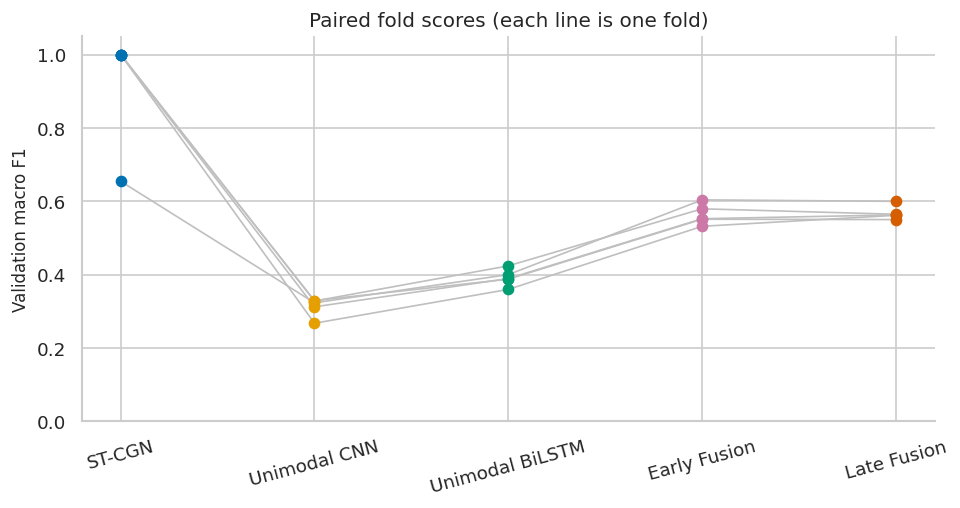

saved outputs/16_paired_folds.png


PosixPath('outputs/16_paired_folds.png')

In [10]:
"""Paired t-tests and Wilcoxon tests on fold-level macro F1."""
def holm_adjust(p_values: np.ndarray) -> np.ndarray:
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values), dtype=np.float64)
    running = 0.0
    count = len(p_values)
    for rank, index in enumerate(order):
        value = min(1.0, (count - rank) * float(p_values[index]))
        value = max(value, running)
        adjusted[index] = value
        running = value
    return adjusted


def paired_effect(reference: np.ndarray, other: np.ndarray) -> dict:
    difference = reference - other
    std = float(np.std(difference, ddof=1))
    cohen = float(np.mean(difference) / std) if std > 0 else float("nan")
    t_result = stats.ttest_rel(reference, other, alternative="two-sided")
    t_p = float(t_result.pvalue)
    t_stat = float(t_result.statistic)
    nonzero = int(np.count_nonzero(~np.isclose(difference, 0.0)))
    wilcoxon_note = "exact two-sided"
    if nonzero == 0:
        w_stat, w_p = float("nan"), float("nan")
        wilcoxon_note = "undefined because every paired difference is zero"
    else:
        w_result = None
        try:
            w_result = stats.wilcoxon(reference, other, alternative="two-sided", zero_method="wilcox", method="exact")
        except (TypeError, ValueError):
            wilcoxon_note = "approximate; exact test unavailable because of ties, zeros, or the installed SciPy"
            try:
                w_result = stats.wilcoxon(reference, other, alternative="two-sided", zero_method="wilcox", method="approx")
            except TypeError:
                w_result = stats.wilcoxon(reference, other, alternative="two-sided", zero_method="wilcox")
                wilcoxon_note = "scipy default"
        w_stat = float(w_result.statistic)
        w_p = float(w_result.pvalue)
    if len(reference) <= 5:
        wilcoxon_note += "; n=5 exact two-sided floor is 0.0625 when all nonzero signs agree"
    return {
        "mean_diff": float(np.mean(difference)),
        "cohen_dz": cohen,
        "t_statistic": t_stat,
        "t_pvalue": t_p,
        "wilcoxon_statistic": w_stat,
        "wilcoxon_pvalue": w_p,
        "wilcoxon_note": wilcoxon_note,
    }


reference_scores = fold_vector(HISTORY, "ST-CGN", "val_f1", CFG.n_folds)
STAT_ROWS = []
for model_name in MODEL_ORDER:
    if model_name == "ST-CGN":
        continue
    other_scores = fold_vector(HISTORY, model_name, "val_f1", CFG.n_folds)
    STAT_ROWS.append({"baseline": model_name, "st_cgn_mean": float(reference_scores.mean()), "baseline_mean": float(other_scores.mean()), **paired_effect(reference_scores, other_scores)})

STATS = pd.DataFrame(STAT_ROWS)
raw_p = STATS["t_pvalue"].to_numpy(dtype=np.float64)
adjustable_p = np.where(np.isfinite(raw_p), raw_p, 1.0)
STATS["t_pvalue_bonferroni"] = np.minimum(adjustable_p * len(STATS), 1.0)
STATS["t_pvalue_holm"] = holm_adjust(adjustable_p)
STATS["t_significant_bonferroni_0.05"] = STATS["t_pvalue_bonferroni"] < 0.05
STATS["direction"] = np.where(STATS["mean_diff"] > 0, "ST-CGN higher", "baseline higher")

def _sig_flag(p_value: float) -> str:
    if not np.isfinite(p_value):
        return "Undefined"
    return "Yes" if p_value < 0.05 else "No"


def _interpretation(mean_diff: float, t_p: float, w_stat: float, w_p: float, same_sign: bool) -> str:
    """State the t-test decision and the N=5 Wilcoxon floor without over-claiming."""
    parts = []
    if np.isfinite(t_p) and t_p < 0.05 and mean_diff > 0:
        parts.append("Paired two-tailed t-test: ST-CGN macro F1 is higher at alpha = 0.05.")
    elif np.isfinite(t_p) and t_p < 0.05 and mean_diff < 0:
        parts.append("Paired two-tailed t-test: the baseline macro F1 is higher at alpha = 0.05.")
    elif np.isfinite(t_p):
        parts.append("Paired two-tailed t-test does not reject equal macro F1 at alpha = 0.05.")
    else:
        parts.append("Paired t-test is undefined because the five paired differences have zero variance.")
    if same_sign and np.isfinite(w_stat) and abs(w_stat) < 1e-8:
        parts.append(
            "Wilcoxon W = 0: the difference has the same sign on all 5 folds. "
            "The exact two-sided p-value is then bounded at p = 2 * (0.5)^5 = 0.0625, "
            "which is the smallest value this test can return for N = 5 and does not cross 0.05."
        )
    elif np.isfinite(w_p) and w_p < 0.05:
        parts.append("Wilcoxon signed-rank test also rejects equal macro F1 at alpha = 0.05.")
    elif np.isfinite(w_p):
        parts.append(
            "Wilcoxon two-sided p = %.4f. With N = 5 the exact test cannot fall below "
            "0.0625 when every nonzero difference has the same sign." % w_p
        )
    else:
        parts.append("Wilcoxon signed-rank test is undefined for these paired differences.")
    if np.isfinite(t_p):
        bonferroni = min(1.0, t_p * 4.0)
        parts.append("Bonferroni threshold for four comparisons is 0.0125 (adjusted p = %.4g)." % bonferroni)
    return " ".join(parts)


print(
    "Paired tests on final-epoch macro F1 across N = 5 folds. "
    "Mean difference = ST-CGN minus baseline. "
    "When ST-CGN wins every fold, Wilcoxon W = 0 and the exact two-sided p-value "
    "is bounded at p = 2 * (0.5)^5 = 0.0625."
)
DISPLAY_ROWS = []
for model_name, row in zip(STATS["baseline"], STATS.to_dict(orient="records")):
    reference = fold_vector(HISTORY, "ST-CGN", "val_f1", CFG.n_folds)
    other = fold_vector(HISTORY, model_name, "val_f1", CFG.n_folds)
    same_sign = bool(np.all(reference > other) or np.all(reference < other))
    DISPLAY_ROWS.append(
        {
            "Comparison": f"ST-CGN vs {model_name}",
            "Mean Diff (Macro F1)": row["mean_diff"],
            "t-statistic": row["t_statistic"],
            "t-test p-value": row["t_pvalue"],
            "t-test Sig (α=0.05)": _sig_flag(row["t_pvalue"]),
            "Wilcoxon stat": row["wilcoxon_statistic"],
            "Wilcoxon p-value": row["wilcoxon_pvalue"],
            "Interpretation": _interpretation(row["mean_diff"], row["t_pvalue"], row["wilcoxon_statistic"], row["wilcoxon_pvalue"], same_sign),
            "Cohen dz": row["cohen_dz"],
            "t-test p-value Bonferroni": row["t_pvalue_bonferroni"],
            "t-test p-value Holm": row["t_pvalue_holm"],
            "Wilcoxon note": row["wilcoxon_note"],
        }
    )
SIGNIFICANCE = pd.DataFrame(DISPLAY_ROWS)
VISIBLE = [
    "Comparison",
    "Mean Diff (Macro F1)",
    "t-statistic",
    "t-test p-value",
    "t-test Sig (α=0.05)",
    "Wilcoxon stat",
    "Wilcoxon p-value",
    "Interpretation",
]
display(SIGNIFICANCE[VISIBLE].style.format({
    "Mean Diff (Macro F1)": "{:.4f}",
    "t-statistic": "{:.4f}",
    "t-test p-value": "{:.4g}",
    "Wilcoxon stat": "{:.4g}",
    "Wilcoxon p-value": "{:.4g}",
}, na_rep="undefined"))
stats_path = OUTPUT_DIR / "statistical_tests.csv"
SIGNIFICANCE.to_csv(stats_path, index=False)
print(f"saved {stats_path}")
for _, item in SIGNIFICANCE.iterrows():
    print(f"\n{item['Comparison']}: {item['Interpretation']}")


fig, ax = plt.subplots(figsize=(8.2, 4.4))
for fold in range(CFG.n_folds):
    ys = [HISTORY[name][fold]["val_f1"][-1] for name in MODEL_ORDER]
    ax.plot(range(len(MODEL_ORDER)), ys, color="0.75", linewidth=1, zorder=1)
for index, model_name in enumerate(MODEL_ORDER):
    scores = fold_vector(HISTORY, model_name, "val_f1", CFG.n_folds)
    ax.scatter(np.full(CFG.n_folds, index), scores, color=MODEL_COLORS[model_name], zorder=2)
ax.set_xticks(range(len(MODEL_ORDER)))
ax.set_xticklabels(list(MODEL_ORDER), rotation=15)
ax.set_ylabel("Validation macro F1")
ax.set_ylim(0, 1.05)
ax.set_title("Paired fold scores (each line is one fold)")
fig.tight_layout()
save_show(fig, "16_paired_folds.png")

## 7. Academic synthesis and literature grounding

### Historical evolution

The first operational description of a crop canopy was not a classifier. It was a ratio. Rouse, Haas, Schell, and Deering (1974) defined the normalized difference vegetation index from red and near infrared reflectance on the first Landsat class instrument, because green biomass raises NIR and chlorophyll absorption lowers red. That index, and the family of two-band transforms that followed, made regional monitoring possible and also fixed its failure mode: many different stresses move the same ratio. A nitrogen deficient canopy, a droughted canopy, and a canopy standing in water can all present a depressed NIR response. The index records the symptom. It does not record the cause.

Sentinel-2 (Drusch et al., 2012) changed the measurement, not the logic. Thirteen bands, 10 m pixels on the visible and NIR, and a five day revisit made field scale multispectral stacks routine. Most production pipelines still collapsed those stacks with a vegetation index, a random forest on hand built features, or, later, a convolutional network trained to imitate a land cover map. Kussul, Lavreniuk, Skakun, and Shelestov (2017) showed that a deep spatial model could separate crop types on satellite tiles better than the index plus classifier recipe. Nevavuori, Narra, and Lipping (2019) showed the same appetite on UAV RGB for yield. Kamilaris and Prenafeta-Boldú (2018) reviewed that wave and already marked the next error as environmental: the picture of the canopy is not the weather that produced it.

The multimodal step in agriculture was concatenation. A CNN embedding, a hand built weather vector, and sometimes a soil table were joined and passed to a fully connected head. Maimaitijiang et al. (2020) is the clear UAV instance: RGB, multispectral, thermal, and structure are each encoded and then stacked for soybean yield. In the taxonomy of Baltrušaitis, Ahuja, and Morency (2019) that is early or intermediate fusion. It is the right model when both signals are global. It is the wrong model when one signal says where a signature sits and the other says whether that signature is drought or water.

Late fusion was the engineering alternative. A visual head and a weather head are trained apart, and a validation set weight, or a small ensemble of such weights, mixes their logits. Li et al. (2022) review this pattern across remote-sensing fusion and separate it from models that keep the spatial lattice. The vote can veto a unimodal false alarm. It cannot read one quadrant and ignore another, because no term in a static weighted sum is a function of both a place and a day.

Sequence models arrived on the weather side alone. The LSTM (Hochreiter and Schmidhuber, 1997) and the bidirectional LSTM (Graves and Schmidhuber, 2005) fit a short daily log. They rank regimes. They never see which part of the field carries the signature the regime is about.

Cross attention is the operator that can build that product. Vaswani et al. (2017) fixed the scaled form used in this notebook. Tsai et al. (2019) showed that cross modal transformers align sequences that are not already on one clock, at a cost quadratic in both lengths. Channel-wise conditioning was already available from squeeze and excitation (Hu, Shen, and Sun, 2018) and from FiLM (Perez et al., 2018). A gate rescales channels. It does not choose a place unless a spatial mask is built as well.

### State of the art methods

Four families are the current reference points, and none of them is the model this label requires.

1. **Index and unimodal convolutional mapping.** NDVI and its red-edge successors, Sentinel-2 time stacks reduced to a per-pixel classifier, and UAV CNNs for yield or species. Strong when the class is a stable spectral type. Blind when two agronomic processes share a spectrum.
2. **Early and mid fusion by concatenation.** The Maimaitijiang-style join, and the broader remote-sensing practice reviewed by Li et al. (2022): encode each sensor, pool, concatenate, classify. This is also what the early-fusion baseline in Section 2 implements, deliberately, so the comparison is against the operator rather than against a starved network.
3. **Late-fusion ensembles.** Independent unimodal scores mixed by learned or validated scalars. This is the late-fusion baseline. Ensembles of this kind are common in operational crop mapping because each head can be swapped when a sensor drops out. The mixture is still a mixture of decisions.
4. **Vision-language models.** CLIP (Radford et al., 2021) learns a global image embedding and a sentence embedding in one contrastive space. Flamingo (Alayrac et al., 2022) keeps a frozen vision encoder and conditions a language model on a perceiver-resampled visual stream for few-shot captioning and visual question answering. Both are the state of the art for open-vocabulary recognition and for interleaved image-text prompting. Both fail the structural requirement here. CLIP discards the spatial lattice before any weather token exists. Flamingo resamples visual features into a short token sequence for a language model; it does not emit a dense mask that selects a field quadrant because a marker burst occurred on a particular day. Adapting either model with a pretrained trunk would also violate the from-scratch constraint of this capstone, and it would not by itself create the missing cross-term.

The relevant SOTA for the mechanism, as opposed to the pretraining corpus, is therefore scaled cross-attention plus feature-wise conditioning, used at a resolution that still distinguishes quadrants. That is a design choice, not a claim that ST-CGN replaces a foundation model on open-world imagery.

### From indices to learned unimodal maps

Operational crop mapping spent a decade on a single sensor and a single inductive bias. Convolutional land cover models showed that a residual or deep spatial stack, trained on multispectral tiles, could separate crop types that hand-built indices only partly resolved (Kussul, Lavreniuk, Skakun, and Shelestov, 2017). Yield models then treated the canopy as a picture: Nevavuori, Narra, and Lipping (2019) predicted yield from RGB with a CNN and no weather trajectory. Reviews of the period (Kamilaris and Prenafeta-Boldú, 2018) already noted that the next errors were environmental rather than architectural. Drought, nitrogen stress, weed pressure, and standing water are not four textures. They are textures whose meaning changes with the recent weather.

The multimodal response in remote sensing was mostly concatenation. Maimaitijiang and colleagues (2020) fused UAV RGB, multispectral, thermal, and structural cues for soybean yield by joining deep features before the predictor. That is early or mid fusion in the taxonomy of Baltrušaitis, Ahuja, and Morency (2019): each modality is summarized, the summaries are stacked, and a joint network is asked to discover the interaction. It works when both signals are global and the interaction is a low-order function of those summaries. It fails when one modality says *where* and the other says *whether*. Li and colleagues (2022), reviewing deep multimodal fusion for remote sensing, make the same distinction between channel stacking and models that keep the spatial lattice.

Late fusion was the other default. Independent heads vote, with weights that are learned once or set by validation accuracy. The vote can reject a unimodal false alarm when the second sensor is confidently healthy. It cannot implement a selection. If the image contains both a drought-like patch and a water like patch, the visual head's logit is a compromise, the weather head's logit is a regime prior, and a static weighted sum of those logits is still a compromise. No coefficient in that sum reads one patch and ignores the other.

Sequence models entered through the weather side. The LSTM (Hochreiter and Schmidhuber, 1997) and its bidirectional form (Graves and Schmidhuber, 2005) fit a short daily log without the data appetite of a temporal transformer. They do not see the canopy. A pure sequence model can rank regimes. It cannot know whether the stressed quadrant is the one the regime is about.

Cross-attention was the general answer in language and video. Vaswani et al. (2017) fixed the scaled product used here. Tsai et al. (2019) showed that cross-modal transformers can align unaligned sequences, at a quadratic cost in the token counts of both streams. Applied naively to a 128×128 map and a 30 day log, that product is the \(O(HWT)\) term Section 3 removes by strided convolution and a fixed grid. Channel-wise conditioning was already available from FiLM (Perez et al., 2018) and from squeeze-and-excitation (Hu, Shen, and Sun, 2018). Those gates rescale features. They do not choose a place unless a spatial mask is built as well.

### The identified research gap

The concrete failure is easy to state with the five classes in this study. Drought stress and waterway encroachment can share a low near-infrared patch. Nitrogen deficiency and a heat-scorched but still healthy canopy can share chlorosis. Weed infestation and a vigorous healthy stand can share a high green texture. Global average pooling, and any late fusion of a globally pooled visual logit with a weather logit, sees the mixture of those signatures and a regime prior. It does not see which signature sits in the quadrant the weather trajectory nominates. On the synthetic generator this is not a metaphor: swapping the trusted quadrant, while keeping the token multiset fixed, changes the label and leaves the early-fusion input unchanged.


Between global concatenation and a full-resolution multimodal transformer there is a missing operating point for field-scale stress labels:

- the spatial map has to survive until the fusion step, because the competing signatures are in different places
- the temporal order has to survive, because the place is named by the position of an event in the log, not by the count of weather tokens
- the coupling has to be an address, a distribution over sites, rather than another concatenation
- the address has to be cheap enough to train on a few thousand paired tiles

Early fusion deletes the first and the second requirement before any layer can learn them. Late fusion never builds the product. A vanilla cross-attention over native pixels satisfies the product and breaks the memory budget. That is the gap ST-CGN is aimed at.

### Novelty of ST-CGN

ST-CGN conditions the spatial map in the middle of the network rather than after both modalities have been destroyed. The query is coordinate-aware, \(Q = W_q F_v + W_p[x, y]\), so a weather state can name a place. The keys are the BiLSTM states, \(K = W_k F_t\), so order is still present when the score is formed. A temporal gate upweights the steps that carry the location code, including a residual on the token embedding so that selection does not wait on a lucky recurrent initialization. A FiLM channel gate, \(g = \sigma(W_g \bar F_t)\), then rescales the visual channels that the mask reads. The head sees the gated local spectrum and the climate summary together. That is early-to-mid conditioning of a dense map by a linguistic query, not a second concatenation and not a late vote.


The residual block, the BiLSTM, scaled dot-product attention, and a sigmoid channel gate are not new. The claim is the combination required by this label: a local residual map, an order-sensitive weather encoder, a spatial softmax of \(QK^\top/\sqrt{d}\) with an explicit coordinate query, a temporal gate that upweights the location-bearing steps, and a climate-conditioned channel gate on the values being read. The 4×4 pool is part of the method, not an afterthought. It is the reason the mask is tractable, and it is also the resolution limit.

The synthetic process is part of the argument rather than a hidden convenience. Swap two quadrants, keep the token multiset fixed, and move only the marker burst: early fusion receives the same vector, the CNN receives the same picture, and the label changes. Any method that solves the test systematically is using order to choose a place. Section 6 asks whether ST-CGN does so more reliably than the four standard operators, under one training protocol. It does not ask whether the generator resembles a particular season in a particular district.

### Algorithmic limitations and trade offs

Parameter count is not the expensive part. A late-fusion network already pays for a CNN and a BiLSTM. ST-CGN adds the projections for \(Q\), \(K\), the coordinate term, and the two gates, which are small next to the convolutions. The expensive part is the score matrix. Formed on the native 32×32 map of a 128×128 tile against \(T = 30\) days, it is \(32^2 \times 30\) scores per sample and the activation memory scales as \(O(B \cdot H' \cdot W' \cdot T)\). The 4×4 adaptive pool cuts that product to \(4^2 \times 30\) scores per sample before the matmul exists. The trade is aliasing: structure smaller than one cell of the grid is averaged away. Raising the grid restores it and restores the quadratic term. A synthetic controlled set can show that this trade is the right one for a quadrant-scale interaction. It cannot stand in for a multi-farm, multi-year survey, and Section 1 says so whenever the Drive files are absent.


- **Resolution.** Anomaly structure smaller than one attention cell is averaged away. Raising `attn_grid` restores it at a quadratic cost in the mask.
- **Coordinate frame.** The position term assumes a stable image axis. A random rotation of the tile, without a matching rewrite of the location code, breaks the address. The model is not rotation-equivariant, and this notebook does not pretend that an augmentation policy would be free.
- **Missing weather.** An all-pad log zeros the readout and leaves the head with a null climate vector. Predictions on those rows fall back toward the head bias. They should be flagged in deployment, not trusted as visual diagnoses.
- **Saturation on the fallback generator.** The privileged linear oracle is separable. If ST-CGN approaches that ceiling, the right reading is that the mask can recover a quadrant-scale interaction that pooling cannot. The wrong reading is that field macro F1 will match the number in `summary_metrics.csv`. Real canopies have illumination, mixed pixels, sensor noise, and labels that do not obey the table in Section 1.
- **Dependence.** Folds share one draw of the generator. The standard deviation across folds understates the uncertainty from sampling a new year or a new region. Five folds also limit the Wilcoxon test, as Section 6 calculates.
- **Class imbalance.** Weighted cross-entropy pushes the minority gradients up. It does not create agronomic examples that were never collected. Waterway encroachment remains the fragile class if its count is small.
- **Compute.** ST-CGN pays for a CNN, a BiLSTM, and a small mask. Late fusion pays for the two encoders and not the mask. The extra FLOPs are justified only while the mask moves macro F1. If a new dataset is solvable from global averages, early fusion is the model that should be deployed.
- **Optimization bias in \(W_q\).** Zero initialization favors coordinate addressing. A problem whose spatial cue is appearance rather than a time code will spend early epochs undoing that bias.
- **Decision risk.** A missed drought and a false waterway alarm have different costs. Macro F1 treats them symmetrically. An operational threshold should be chosen on recall for the costly class, not on the headline macro score. This notebook is a comparative study of representations, not a dispatch tool for irrigation or spraying.

### Prior-work drawbacks in one place

| Prior pattern | Representative source | Drawback for this label |
| --- | --- | --- |
| Unimodal CNN on a canopy tile | Kussul et al., 2017; Nevavuori et al., 2019 | Spectrally similar stresses stay entangled once weather is the deciding factor |
| Unimodal recurrent weather model | Hochreiter and Schmidhuber, 1997 | No access to which part of the field carries the signature |
| Early feature concatenation | Maimaitijiang et al., 2020; Baltrušaitis et al., 2019 | Destroys spatial layout and temporal order before the interaction |
| Static late fusion of logits | Baltrušaitis et al., 2019 | No cross-term; a weighted vote cannot select a site |
| Full cross-modal transformer | Tsai et al., 2019; Vaswani et al., 2017 | Right operator, native \(HW \times T\) memory |
| Channel gating alone | Hu et al., 2018; Perez et al., 2018 | Rescales channels globally and still reads every location |

ST-CGN keeps the local map those CNN papers showed how to build, the ordered state those recurrent papers showed how to build, and a masked readout whose support is a pooled grid rather than the raw lattice. The empirical question, answered in Sections 5 and 6 rather than in this prose, is whether that readout beats the four operators that omit one of those pieces.

### References

Alayrac, J.-B., Donahue, J., Luc, P., Miech, A., Barr, I., Hasson, Y., Lenc, K., Mensch, A., Millican, K., Reynolds, M., Ring, R., Rutherford, E., Cabi, S., Han, T., Gong, Z., Samangooei, S., Monteiro, M., Menick, J., Borgeaud, S., Brock, A., Nematzadeh, A., Sharifzadeh, S., Binkowski, M., Barreira, R., Vinyals, O., Zisserman, A., and Simonyan, K. (2022). Flamingo: a visual language model for few-shot learning. In *NeurIPS*.

Baltrušaitis, T., Ahuja, C., and Morency, L.-P. (2019). Multimodal machine learning: A survey and taxonomy. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 41(2), 423–443.

Drusch, M., Del Bello, U., Carlier, S., Colin, O., Fernandez, V., Gascon, F., Hoersch, B., Isola, C., Laberinti, P., Martimort, P., Meygret, A., Spoto, F., Sy, O., Marchese, F., and Bargellini, P. (2012). Sentinel-2: ESA's optical high-resolution mission for GMES operational services. *Remote Sensing of Environment*, 120, 25–36.

Graves, A., and Schmidhuber, J. (2005). Framewise phoneme classification with bidirectional LSTM and other neural network architectures. *Neural Networks*, 18(5–6), 602–610.

Hendrycks, D., and Gimpel, K. (2016). Gaussian error linear units (GELUs). arXiv:1606.08415.

Hochreiter, S., and Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.

Hu, J., Shen, L., and Sun, G. (2018). Squeeze-and-excitation networks. In *CVPR*.

Jozefowicz, R., Zaremba, W., and Sutskever, I. (2015). An empirical exploration of recurrent network architectures. In *ICML*.

Kamilaris, A., and Prenafeta-Boldú, F. X. (2018). Deep learning in agriculture: A survey. *Computers and Electronics in Agriculture*, 147, 70–90.

Kussul, N., Lavreniuk, M., Skakun, S., and Shelestov, A. (2017). Deep learning classification of land cover and crop types using remote sensing data. *IEEE Geoscience and Remote Sensing Letters*, 14(5), 778–782.

Li, J., Hong, D., Gao, L., Yao, J., Zheng, K., Zhang, B., and Chanussot, J. (2022). Deep learning in multimodal remote sensing data fusion: A comprehensive review. *International Journal of Applied Earth Observation and Geoinformation*, 112, 102926.

Liu, R., Lehman, J., Molino, P., Such, F. P., Frank, E., Sergeev, A., and Yosinski, J. (2018). An intriguing failing of convolutional neural networks and the CoordConv solution. In *NeurIPS*.

Loshchilov, I., and Hutter, F. (2017). SGDR: Stochastic gradient descent with warm restarts. In *ICLR*.

Loshchilov, I., and Hutter, F. (2019). Decoupled weight decay regularization. In *ICLR*.

Maimaitijiang, M., Sagan, V., Sidike, P., Hartling, S., Esposito, F., and Fritschi, F. B. (2020). Soybean yield prediction from UAV using multimodal data fusion and deep learning. *Remote Sensing of Environment*, 237, 111599.

Nevavuori, P., Narra, N., and Lipping, T. (2019). Crop yield prediction with deep convolutional neural networks. *Computers and Electronics in Agriculture*, 163, 104859.

Perez, E., Strub, F., de Vries, H., Dumoulin, V., and Courville, A. (2018). FiLM: Visual reasoning with a general conditioning layer. In *AAAI*.

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., and Sutskever, I. (2021). Learning transferable visual models from natural language supervision. In *ICML*.

Rouse, J. W., Haas, R. H., Schell, J. A., and Deering, D. W. (1974). Monitoring vegetation systems in the Great Plains with ERTS. In *Third Earth Resources Technology Satellite-1 Symposium*, NASA SP-351, 309–317.

Sokolova, M., and Lapalme, G. (2009). A systematic analysis of performance measures for classification tasks. *Information Processing & Management*, 45(4), 427–437.

Student. (1908). The probable error of a mean. *Biometrika*, 6(1), 1–25. The paired *t* procedure used in Section 6 is the dependent-sample form of this test.

Tsai, Y.-H. H., Bai, S., Liang, P. P., Kolter, J. Z., Morency, L.-P., and Salakhutdinov, R. (2019). Multimodal transformer for unaligned multimodal language sequences. In *ACL*.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., and Polosukhin, I. (2017). Attention is all you need. In *NeurIPS*.

Wilcoxon, F. (1945). Individual comparisons by ranking methods. *Biometrics Bulletin*, 1(6), 80–83.

### AI Usage Statement 

AI tools were utilized strictly in an assistive capacity during the development of this capstone project. Gemini 3.1 Pro was employed as a deep research assistant to explore methodologies, assist with the literature review, and identify foundational journal publications relevant to the study's domain. Grok 4.7 served as a technical programming assistant during the implementation phase to help troubleshoot PyTorch tensor operations, diagnose bugs, and suggest code fixes. Additionally, Grok 4.7 was utilized to format the final written text into LaTeX for PDF typesetting.

Despite this technical assistance, the architectural design of the ST-CGN, the experimental protocol, the validation against the baselines, the interpretation of the fold scores, and the final academic narrative are entirely the original work of mine. All produced code and the final report were authored by me, with the AI tools functioning solely as supplementary aids. I comprehensively reviewed every equation, table and claim and takes full responsibility for the entirety of this submission.